# Mission DS01: Exploratory Data Analysis on ShopSmart Retail Data

**Programme:** AnalystLab Africa Experience Lab, Week 1 (Data Science Track)
**Author:** Molemi Molokoane
**Client:** ShopSmart Retail Ltd.

ShopSmart has a year of customer, product, sales, inventory and returns data. Before any predictive
model is built, management wants to understand that data: how clean it is, where the revenue comes
from, and what patterns could support machine learning later.

This notebook follows the Data Science lifecycle:

| # | Section | What happens |
|---|---------|--------------|
| 1 | Environment setup | Libraries, plotting style, paths |
| 2 | Load the data | Read all nine CSVs and inspect them |
| 3 | Data cleaning | Duplicates, missing values, types, dates, names, inconsistent values |
| 4 | Exploratory analysis | Headline KPIs |
| 5 | Visualisation | Ten required charts |
| 6 | Correlation analysis | Matrix, heatmap, pair plot |
| 7 | Feature engineering | Eight new features for future models |
| 8 | Business questions | Ten questions answered with tables and charts |
| 9 | Bonus | Customer segmentation with K-Means |

## Part 1: Environment setup

The project runs in a Python 3 virtual environment. To reproduce it:

```bash
python -m venv .venv
.venv\Scripts\activate          # Windows  (source .venv/bin/activate on macOS/Linux)
pip install -r requirements.txt
jupyter notebook Week1_EDA.ipynb
```

In [1]:
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import missingno as msno
import numpy as np
import pandas as pd
import seaborn as sns

print(f"Python      {sys.version.split()[0]}")
for lib in (pd, np, matplotlib, sns, msno):
    print(f"{lib.__name__:<11} {lib.__version__}")

Python      3.13.14
pandas      3.0.6
numpy       2.5.4
matplotlib  3.11.2
seaborn     0.13.2
missingno   0.5.2


In [2]:
# ---- Paths -----------------------------------------------------------------
RAW_DIR = Path("../data")              # raw CSVs are shared at the repo root
CLEAN_DIR = Path("Cleaned_Data")
VIZ_DIR = Path("Visualizations")
CLEAN_DIR.mkdir(exist_ok=True)
VIZ_DIR.mkdir(exist_ok=True)

# ---- Display options -------------------------------------------------------
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)

# ---- Plot style ------------------------------------------------------------
# One accent hue for single-series charts, a fixed categorical order for
# multi-series charts, and quiet grey axes so the data stands out.
PRIMARY = "#2a78d6"
ACCENT = "#eb6834"
MUTED = "#9a9893"
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
               "#e87ba4", "#008300", "#6250d6", "#e34948"]

sns.set_theme(style="whitegrid", palette=CATEGORICAL)
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.edgecolor": "#d0cfca",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "grid.color": "#ecebe7",
    "axes.spines.top": False,
    "axes.spines.right": False,
})


def naira(x, _pos=None, digits=2):
    """Format naira compactly: 1_250_000 -> '₦1.25M'."""
    for div, suffix in ((1e9, "B"), (1e6, "M"), (1e3, "K")):
        if abs(x) >= div:
            return f"₦{x / div:,.{digits if div > 1e3 else 0}f}{suffix}"
    return f"₦{x:,.0f}"


# Axis ticks need fewer digits than value labels.
NAIRA_AXIS = mticker.FuncFormatter(lambda x, _pos: naira(x, digits=0))


def save_fig(fig, name):
    """Save a figure to the Visualizations folder and show it inline."""
    fig.savefig(VIZ_DIR / f"{name}.png")
    plt.show()

## Part 2: Load the data

Nine CSV tables were provided, plus a data dictionary. Some files start with a UTF-8 byte-order
mark, so every file is read with `encoding="utf-8-sig"` to keep the first column name clean.

In [3]:
RAW_FILES = {
    "customers":   "ALA_ShopSmart_Customers.csv",
    "products":    "ShopSmart_Products.csv",
    "orders":      "ShopSmart_Orders.csv",
    "order_items": "ShopSmart_Order_Items.csv",
    "stores":      "ShopSmart_Stores.csv",
    "returns":     "ShopSmart_Returns.csv",
    "employees":   "ShopSmart_Employees.csv",
    "suppliers":   "ShopSmart_Suppliers.csv",
    "inventory":   "ShopSmart_Inventory.csv",
}


def load_raw(files: dict) -> dict:
    """Read every CSV into a dict of DataFrames keyed by table name."""
    return {name: pd.read_csv(RAW_DIR / fname, encoding="utf-8-sig") for name, fname in files.items()}


raw = load_raw(RAW_FILES)
data_dictionary = pd.read_csv(RAW_DIR / "ShopSmart_Data_Dictionary.csv", encoding="utf-8-sig")

pd.DataFrame({
    "file": RAW_FILES.values(),
    "rows": [df.shape[0] for df in raw.values()],
    "columns": [df.shape[1] for df in raw.values()],
}, index=raw.keys())

,file,rows,columns
customers,ALA_ShopSmart_Customers.csv,5000,11
products,ShopSmart_Products.csv,500,7
orders,ShopSmart_Orders.csv,50000,12
order_items,ShopSmart_Order_Items.csv,50000,7
stores,ShopSmart_Stores.csv,25,6
returns,ShopSmart_Returns.csv,2500,5
employees,ShopSmart_Employees.csv,125,6
suppliers,ShopSmart_Suppliers.csv,489,6
inventory,ShopSmart_Inventory.csv,500,6


### 2.1 Inspect each table

For every table: `head()`, `tail()`, shape, columns, data types and missing values.

In [4]:
def inspect(name: str, df: pd.DataFrame, n: int = 3) -> None:
    """Print a compact structural overview of one table."""
    print(f"{'=' * 90}\n{name.upper()}  shape={df.shape}\n{'=' * 90}")
    print("Columns:", list(df.columns))
    overview = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "unique": df.nunique(),
    })
    print(overview.to_string(), "\n")
    print(f"head({n}):")
    print(df.head(n).to_string(), "\n")
    print(f"tail({n}):")
    print(df.tail(n).to_string(), "\n")


for table_name, table in raw.items():
    inspect(table_name, table)

CUSTOMERS  shape=(5000, 11)
Columns: ['Customer_ID', 'First_Name', 'Last_Name', 'Gender', 'Age', 'Email', 'Phone', 'City', 'State', 'Registration_Date', 'Customer_Segment']
                   dtype  missing  unique
Customer_ID          str        0    5000
First_Name           str        0     595
Last_Name            str        0     916
Gender               str        0       2
Age                int64        0      53
Email                str        0    4951
Phone                str        0    4996
City                 str        0      10
State                str        0      10
Registration_Date    str        0     995
Customer_Segment     str        0       3 

head(3):
  Customer_ID First_Name Last_Name Gender  Age                     Email                  Phone   City  State Registration_Date Customer_Segment
0   CUST00001   Michelle   Russell   Male   65  elizabethfox@example.net      (701)981-5738x907  Abuja  Abuja         10/9/2023           Bronze
1   CUST00002      Sar

### 2.2 Missing values at a glance

`missingno` draws one bar per column showing how complete it is. A full bar means no missing values.

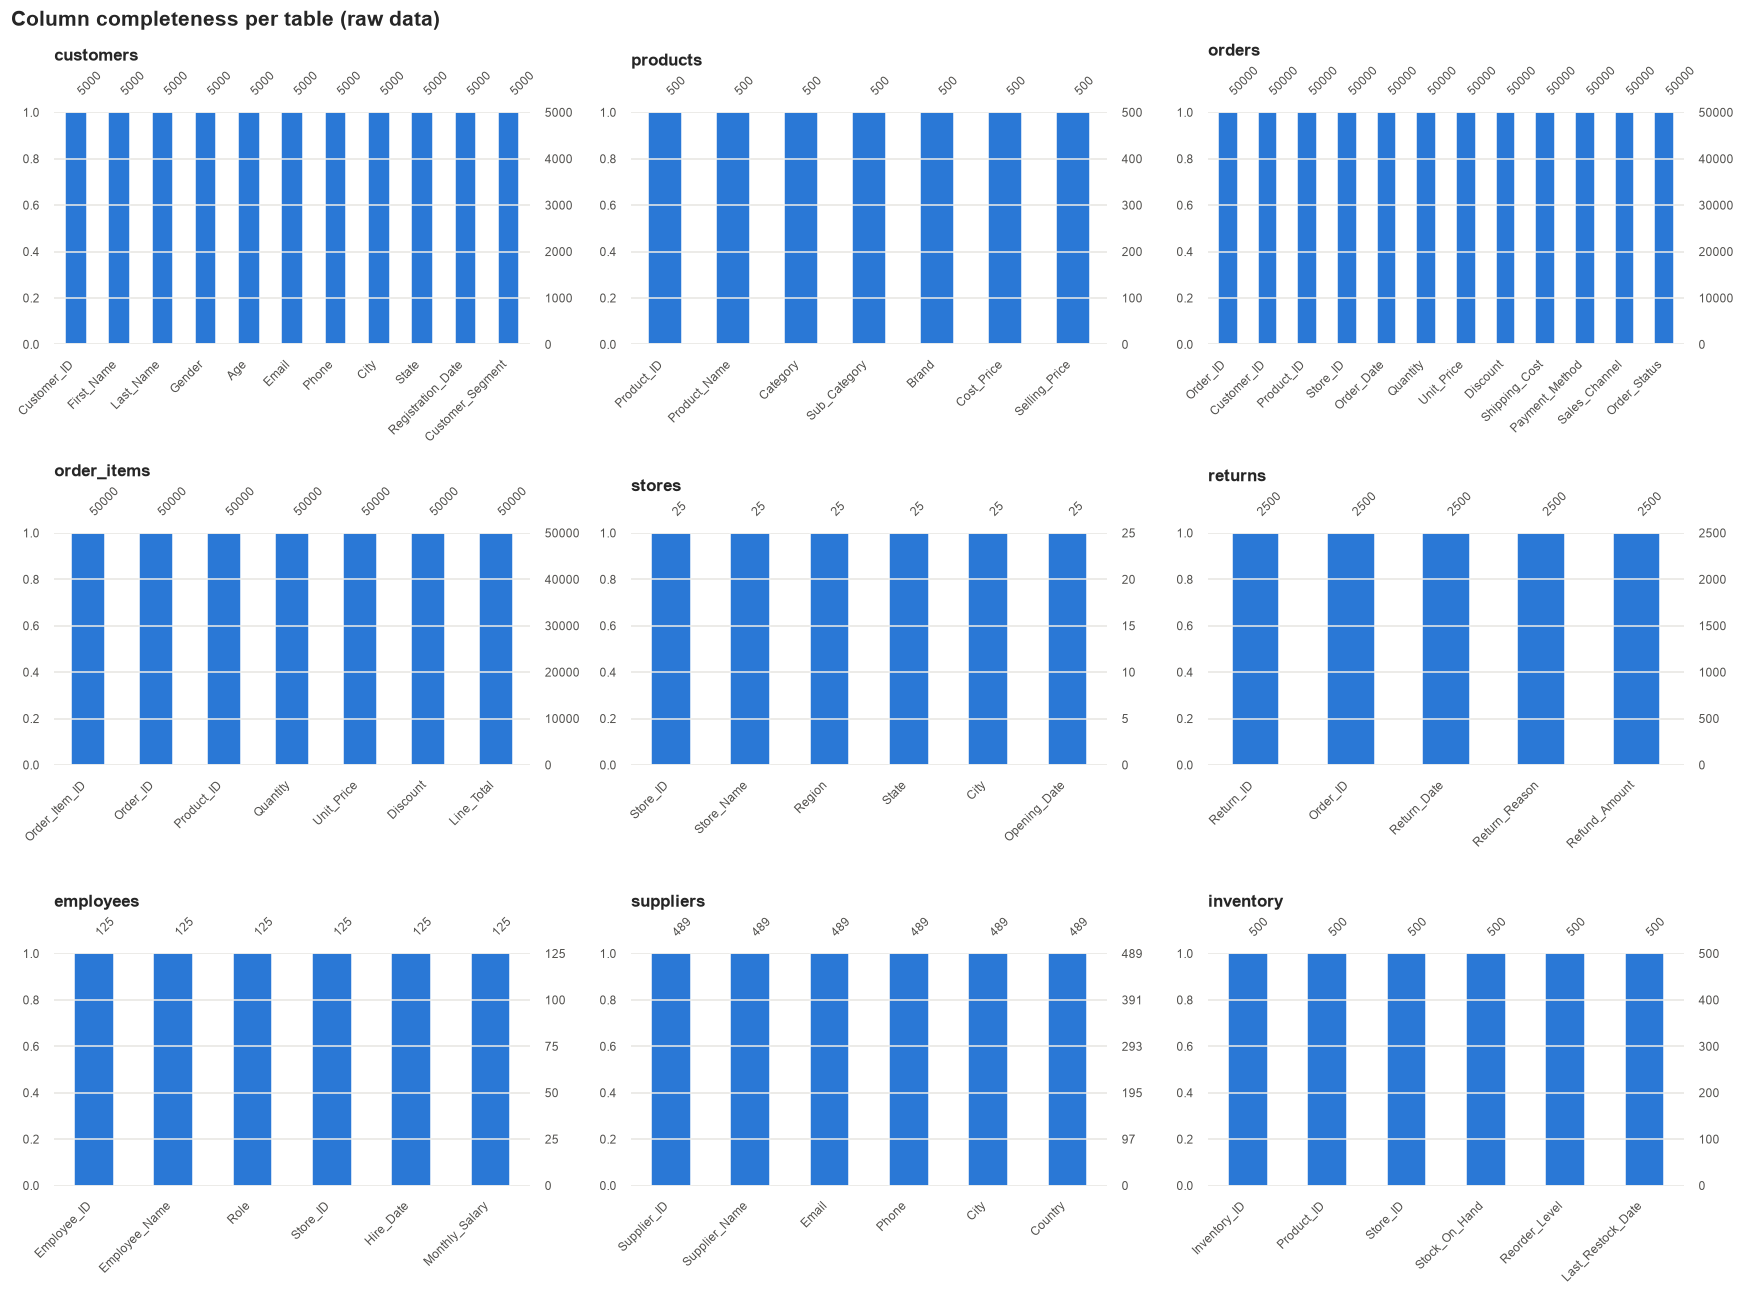

Total missing cells across all tables: 0


In [5]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, (table_name, table) in zip(axes.flat, raw.items()):
    msno.bar(table, ax=ax, fontsize=8, color=PRIMARY)
    ax.set_title(table_name, fontsize=11, loc="left")
fig.suptitle("Column completeness per table (raw data)", fontsize=14, fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
save_fig(fig, "00_missing_values_overview")

total_missing = sum(int(df.isna().sum().sum()) for df in raw.values())
print(f"Total missing cells across all tables: {total_missing}")

### 2.3 Data dictionary coverage

The dictionary only documents five of the nine tables, and every description is a placeholder
(`"<column> field"`). Section 3 adds proper descriptions for the columns we use.

In [6]:
print("Tables documented:", sorted(data_dictionary["Dataset"].unique()))
print("Tables missing   :", sorted({"Employees", "Suppliers", "Inventory", "Order_Items"}))
data_dictionary.head()

Tables documented: ['Customers', 'Orders', 'Products', 'Returns', 'Stores']
Tables missing   : ['Employees', 'Inventory', 'Order_Items', 'Suppliers']


,Dataset,Column,Description
0,Customers,Customer_ID,Customer_ID field
1,Customers,First_Name,First_Name field
2,Customers,Last_Name,Last_Name field
3,Customers,Gender,Gender field
4,Customers,Age,Age field


### 2.4 First observations

* **Size:** 5,000 customers, 500 products, 25 stores and 50,000 orders from 1 Jan to 31 Dec 2025.
* **Completeness:** no table has any missing values.
* **Types:** dates load as text and have to be converted. IDs are text, and money columns are already numeric.
* **Orders vs Order_Items:** both have 50,000 rows. Section 3 checks whether they hold the same information.

## Part 3: Data cleaning

Every step below is recorded in a **cleaning log** (`log_step`), which is saved with the cleaned
data. The raw tables in `raw` are never modified. All work happens on copies in `clean`.

In [7]:
clean = {name: df.copy() for name, df in raw.items()}
cleaning_log = []


def log_step(table: str, step: str, detail: str, rows_affected: int = 0) -> None:
    """Record one cleaning action so the process is auditable."""
    cleaning_log.append({"table": table, "step": step, "detail": detail, "rows_affected": int(rows_affected)})

### 3.1 Rename columns

All column names become lower `snake_case` (`Customer_ID` becomes `customer_id`). This makes them
consistent across tables and easy to type.

In [8]:
def to_snake(col: str) -> str:
    return col.strip().lower().replace(" ", "_")


for name, df in clean.items():
    clean[name] = df.rename(columns=to_snake)
    log_step(name, "rename columns", "converted column names to snake_case")

clean["orders"].columns.tolist()

['order_id',
 'customer_id',
 'product_id',
 'store_id',
 'order_date',
 'quantity',
 'unit_price',
 'discount',
 'shipping_cost',
 'payment_method',
 'sales_channel',
 'order_status']

### 3.2 Remove duplicates

Two kinds of duplicate are checked: identical rows, and repeated primary keys.

In [9]:
PRIMARY_KEYS = {
    "customers": "customer_id", "products": "product_id", "orders": "order_id",
    "order_items": "order_item_id", "stores": "store_id", "returns": "return_id",
    "employees": "employee_id", "suppliers": "supplier_id", "inventory": "inventory_id",
}

dup_report = []
for name, df in clean.items():
    pk = PRIMARY_KEYS[name]
    full_dups, pk_dups = df.duplicated().sum(), df[pk].duplicated().sum()
    dup_report.append({"table": name, "primary_key": pk, "duplicate_rows": full_dups, "duplicate_keys": pk_dups})
    if full_dups:
        clean[name] = df.drop_duplicates()
        log_step(name, "remove duplicates", "dropped identical rows", full_dups)
pd.DataFrame(dup_report).set_index("table")

,primary_key,duplicate_rows,duplicate_keys
table,,,
customers,customer_id,0,0
products,product_id,0,0
orders,order_id,0,0
order_items,order_item_id,0,0
stores,store_id,0,0
returns,return_id,0,0
employees,employee_id,0,0
suppliers,supplier_id,0,0
inventory,inventory_id,0,0


No table has duplicate rows or duplicate primary keys. **Returns** has a subtler problem: some
orders were returned more than once.

In [10]:
repeat_returns = clean["returns"][clean["returns"]["order_id"].duplicated(keep=False)].sort_values("order_id")
print(f"Orders with more than one return record: {repeat_returns['order_id'].nunique()}")
repeat_returns.head(6)

Orders with more than one return record: 56


,return_id,order_id,return_date,return_reason,refund_amount
221,RET00222,ORD002471,1/1/2025,Wrong Item,35528
1896,RET01897,ORD002471,11/5/2025,Late Delivery,22944
576,RET00577,ORD002689,7/21/2025,Customer Changed Mind,44658
554,RET00555,ORD002689,4/27/2025,Wrong Item,48496
1479,RET01480,ORD003065,11/13/2025,Damaged,33216
195,RET00196,ORD003065,10/2/2025,Wrong Item,14858


Each order holds only one product line, so an order can only be returned once. We keep the
**earliest** return record (lowest `return_id`) for each order and drop the rest.

In [11]:
before = len(clean["returns"])
clean["returns"] = (clean["returns"].sort_values("return_id")
                    .drop_duplicates(subset="order_id", keep="first")
                    .reset_index(drop=True))
log_step("returns", "remove duplicates", "kept first return record per order_id", before - len(clean["returns"]))
print(f"Returns: {before:,} -> {len(clean['returns']):,} rows")

Returns: 2,500 -> 2,442 rows


### 3.3 Handle missing values

Part 2 found **no missing values** in any table. The function below still applies a clear policy so
the pipeline is safe if future extracts have gaps:

* **IDs or dates missing:** drop the row, because it cannot be linked or placed in time.
* **Numbers missing:** fill with the column median, which is robust to outliers.
* **Text missing:** fill with `"Unknown"`.

In [12]:
def handle_missing(df: pd.DataFrame, table: str) -> pd.DataFrame:
    """Apply the missing-value policy and log what was changed."""
    df = df.copy()
    critical = [c for c in df.columns if c.endswith("_id") or c.endswith("_date")]
    n_before = len(df)
    df = df.dropna(subset=critical)
    if n_before - len(df):
        log_step(table, "missing values", f"dropped rows missing {critical}", n_before - len(df))
    for col in df.columns.difference(critical):
        n_missing = df[col].isna().sum()
        if not n_missing:
            continue
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            df[col] = df[col].fillna("Unknown")
        log_step(table, "missing values", f"filled {col}", n_missing)
    return df


for name in clean:
    clean[name] = handle_missing(clean[name], name)

print("Missing cells after cleaning:", sum(int(df.isna().sum().sum()) for df in clean.values()))

Missing cells after cleaning: 0


### 3.4 Convert dates and fix data types

All dates use the US format `M/D/YYYY` (for example `7/19/2025`). Parsing them with an explicit
format avoids day/month mix-ups, and `errors="coerce"` would show any value that does not fit.

In [13]:
DATE_COLUMNS = {
    "customers": ["registration_date"], "orders": ["order_date"], "stores": ["opening_date"],
    "returns": ["return_date"], "employees": ["hire_date"], "inventory": ["last_restock_date"],
}

for name, cols in DATE_COLUMNS.items():
    for col in cols:
        parsed = pd.to_datetime(clean[name][col], format="%m/%d/%Y", errors="coerce")
        bad = parsed.isna().sum()
        clean[name][col] = parsed
        log_step(name, "convert dates", f"{col} -> datetime64 (unparseable: {bad})")
        print(f"{name:<10} {col:<18} {parsed.min().date()} → {parsed.max().date()}   unparseable={bad}")

customers  registration_date  2023-01-01 → 2025-09-27   unparseable=0
orders     order_date         2025-01-01 → 2025-12-31   unparseable=0
stores     opening_date       2020-01-31 → 2022-01-20   unparseable=0


returns    return_date        2025-01-01 → 2025-12-31   unparseable=0
employees  hire_date          2019-01-07 → 2026-08-10   unparseable=0
inventory  last_restock_date  2026-07-13 → 2026-10-10   unparseable=0


In [14]:
# Low-cardinality text columns become 'category' (smaller in memory, faster to group by).
CATEGORICAL_COLUMNS = {
    "customers": ["gender", "city", "state", "customer_segment"],
    "orders": ["payment_method", "sales_channel", "order_status"],
    "products": ["category", "sub_category"],
    "stores": ["region", "state", "city"],
    "returns": ["return_reason"],
    "employees": ["role"],
    "suppliers": ["country"],
}
for name, cols in CATEGORICAL_COLUMNS.items():
    for col in cols:
        clean[name][col] = clean[name][col].astype(str).str.strip().str.title().astype("category")
    log_step(name, "fix data types", f"trimmed, title-cased and categorised {cols}")

# Money columns must be numeric. Coerce defensively and round to kobo.
MONEY_COLUMNS = {
    "products": ["cost_price", "selling_price"],
    "orders": ["unit_price", "shipping_cost"],
    "order_items": ["unit_price", "line_total"],
    "returns": ["refund_amount"],
    "employees": ["monthly_salary"],
}
for name, cols in MONEY_COLUMNS.items():
    for col in cols:
        clean[name][col] = pd.to_numeric(clean[name][col], errors="coerce").round(2)
    log_step(name, "fix data types", f"ensured {cols} are numeric")

clean["orders"].dtypes

order_id                     str
customer_id                  str
product_id                   str
store_id                     str
order_date        datetime64[us]
quantity                   int64
unit_price                 int64
discount                   int64
shipping_cost              int64
payment_method          category
sales_channel           category
order_status            category
dtype: object

### 3.5 Check inconsistent values

Every table loads without errors, but several business rules are broken. Each check below shows the
evidence first, then the fix.

#### (a) Range checks on numeric fields

In [15]:
range_checks = pd.DataFrame([
    ("customers.age", clean["customers"]["age"].between(18, 100).mean()),
    ("orders.quantity > 0", (clean["orders"]["quantity"] > 0).mean()),
    ("orders.unit_price > 0", (clean["orders"]["unit_price"] > 0).mean()),
    ("orders.discount in 0-100", clean["orders"]["discount"].between(0, 100).mean()),
    ("orders.shipping_cost >= 0", (clean["orders"]["shipping_cost"] >= 0).mean()),
    ("products.cost_price > 0", (clean["products"]["cost_price"] > 0).mean()),
    ("products.selling > cost", (clean["products"]["selling_price"] > clean["products"]["cost_price"]).mean()),
    ("inventory.stock_on_hand >= 0", (clean["inventory"]["stock_on_hand"] >= 0).mean()),
    ("returns.refund_amount > 0", (clean["returns"]["refund_amount"] > 0).mean()),
], columns=["rule", "share_passing"])
range_checks.style.format({"share_passing": "{:.1%}"})

,rule,share_passing
0,customers.age,100.0%
1,orders.quantity > 0,100.0%
2,orders.unit_price > 0,100.0%
3,orders.discount in 0-100,100.0%
4,orders.shipping_cost >= 0,100.0%
5,products.cost_price > 0,100.0%
6,products.selling > cost,100.0%
7,inventory.stock_on_hand >= 0,100.0%
8,returns.refund_amount > 0,100.0%


All basic range rules pass.

#### (b) Orders vs Order_Items: one table or two?

In [16]:
o, oi = clean["orders"], clean["order_items"]
same = {col: bool((o[col].values == oi[col].values).all())
        for col in ["order_id", "product_id", "quantity", "unit_price", "discount"]}
print("Row-for-row identical columns:", same)
print("Order lines per order:", oi.groupby("order_id").size().max())

Row-for-row identical columns: {'order_id': True, 'product_id': True, 'quantity': True, 'unit_price': True, 'discount': True}
Order lines per order: 1


Order_Items repeats the order lines exactly, one line per order. Its only extra column is
`line_total`. We use **Orders** as the fact table and recalculate the line total ourselves (see (c)).

#### (c) `discount` is a percentage, but `line_total` treats it as naira

In [17]:
print("Distinct discount values:", sorted(oi["discount"].unique()))
as_naira = oi["quantity"] * oi["unit_price"] - oi["discount"]
as_percent = oi["quantity"] * oi["unit_price"] * (1 - oi["discount"] / 100)
print(f"line_total == qty*price - discount       : {(as_naira == oi['line_total']).mean():.1%}")
print(f"line_total == qty*price*(1 - discount/100): {(as_percent.round() == oi['line_total']).mean():.1%}")
print(f"Example: 1 x ₦77,989 with discount=10 -> line_total ₦{oi.loc[0, 'line_total']:,}")

Distinct discount values: [np.int64(0), np.int64(5), np.int64(10), np.int64(15), np.int64(20)]
line_total == qty*price - discount       : 100.0%
line_total == qty*price*(1 - discount/100): 20.3%
Example: 1 x ₦77,989 with discount=10 -> line_total ₦77,979


`discount` only takes the values 0, 5, 10, 15 and 20, which are typical **percentage** rates. A
discount of ₦10 on a ₦77,989 item makes no business sense. The source system subtracted the rate
as a naira amount, which understates every discount.

**Fix:** keep `discount` and rename it `discount_pct`. Recalculate the order value as
`gross_sales = quantity × unit_price` and `net_sales = gross_sales × (1 − discount_pct/100)`.
The original `line_total` is kept as `line_total_source` for traceability.

In [18]:
orders = clean["orders"].rename(columns={"discount": "discount_pct"})
orders["gross_sales"] = orders["quantity"] * orders["unit_price"]
orders["discount_amount"] = (orders["gross_sales"] * orders["discount_pct"] / 100).round(2)
orders["net_sales"] = orders["gross_sales"] - orders["discount_amount"]
orders["line_total_source"] = clean["order_items"]["line_total"].values
clean["orders"] = orders
log_step("orders", "inconsistent values",
         "discount treated as % (values 0-20); recomputed gross_sales, discount_amount, net_sales", len(orders))

print(f"Total discount, source logic : ₦{(orders['gross_sales'] - orders['line_total_source']).sum():,.0f}")
print(f"Total discount, corrected    : ₦{orders['discount_amount'].sum():,.0f}")

Total discount, source logic : ₦498,530
Total discount, corrected    : ₦756,475,868


#### (d) Store names are not unique

In [19]:
clean["stores"]["store_name"].value_counts().head()

store_name
ShopSmart Abuja     4
ShopSmart Lagos     4
ShopSmart Ibadan    4
ShopSmart Asaba     3
ShopSmart Kaduna    3
Name: count, dtype: int64

There are 25 stores but only 10 distinct names. Four stores are all called "ShopSmart Abuja", for
example. A chart by `store_name` would quietly merge different stores. **Fix:** add a unique
`store_label`, such as "Abuja (STR001)".

In [20]:
stores = clean["stores"]
stores["store_label"] = stores["city"].astype(str) + " (" + stores["store_id"] + ")"
log_step("stores", "inconsistent values", "added unique store_label (names repeat across stores)", len(stores))
stores[["store_id", "store_name", "store_label"]].head()

,store_id,store_name,store_label
0,STR001,ShopSmart Abuja,Abuja (STR001)
1,STR002,ShopSmart Kano,Kano (STR002)
2,STR003,ShopSmart Lagos,Lagos (STR003)
3,STR004,ShopSmart Asaba,Asaba (STR004)
4,STR005,ShopSmart Enugu,Enugu (STR005)


#### (e) Region does not match State

In [21]:
pd.crosstab(stores["state"], stores["region"])

region,East,North,South,West
state,,,,
Abuja,1,1,2,0
Anambra,1,0,0,0
Delta,0,1,1,1
Enugu,0,0,1,0
Kaduna,1,0,1,1
Kano,0,0,0,1
Lagos,1,1,1,1
Ogun,1,0,1,0
Oyo,2,1,1,0


The same state appears in several regions: Lagos stores are tagged North, South, East *and* West.
Abuja is tagged "East", and Kano and Kaduna (both in the North) are tagged "West". The `region`
field cannot be trusted for geographic analysis.

**Fix:** keep it as `region_original` and add `geo_zone`, using Nigeria's six official
geopolitical zones based on the store's state. Regional analysis in this notebook uses `geo_zone`.

In [22]:
GEO_ZONES = {
    "Abuja": "North Central", "Kano": "North West", "Kaduna": "North West",
    "Lagos": "South West", "Ogun": "South West", "Oyo": "South West",
    "Delta": "South South", "Rivers": "South South",
    "Enugu": "South East", "Anambra": "South East",
}
stores = stores.rename(columns={"region": "region_original"})
stores["geo_zone"] = stores["state"].astype(str).map(GEO_ZONES).astype("category")
assert stores["geo_zone"].notna().all(), "every store state must map to a zone"
clean["stores"] = stores
log_step("stores", "inconsistent values", "region inconsistent with state; added geo_zone from state", len(stores))
stores[["store_label", "state", "region_original", "geo_zone"]].head(8)

,store_label,state,region_original,geo_zone
0,Abuja (STR001),Abuja,East,North Central
1,Kano (STR002),Kano,West,North West
2,Lagos (STR003),Lagos,South,South West
3,Asaba (STR004),Delta,South,South South
4,Enugu (STR005),Enugu,South,South East
5,Kaduna (STR006),Kaduna,East,North West
6,Ibadan (STR007),Oyo,North,South West
7,Port Harcourt (STR008),Rivers,North,South South


#### (f) Returns that cannot be right

In [23]:
ret = clean["returns"].merge(orders[["order_id", "order_date", "order_status", "net_sales"]], on="order_id", how="left")
ret["return_before_order"] = ret["return_date"] < ret["order_date"]
ret["refund_exceeds_sale"] = ret["refund_amount"] > ret["net_sales"]
ret["order_not_completed"] = ret["order_status"] != "Completed"

pd.DataFrame({
    "issue": ["Return dated before its order", "Refund larger than the order value", "Return on a Cancelled/Pending order"],
    "rows": [ret["return_before_order"].sum(), ret["refund_exceeds_sale"].sum(), ret["order_not_completed"].sum()],
    "share": [ret["return_before_order"].mean(), ret["refund_exceeds_sale"].mean(), ret["order_not_completed"].mean()],
}).style.format({"share": "{:.1%}"})

,issue,rows,share
0,Return dated before its order,1225,50.2%
1,Refund larger than the order value,299,12.2%
2,Return on a Cancelled/Pending order,1644,67.3%


About half of all returns are dated *before* the order was placed, and two thirds relate to orders
that were never completed. Both point to a weak link between the returns system and the order
system. Deleting these rows would remove most of the returns data, so we **keep them and add flags**
(`return_before_order`, `refund_exceeds_sale`, `order_not_completed`). That way any analysis can
include or exclude them, and the issue is reported to ShopSmart as a data-quality risk.

In [24]:
clean["returns"] = ret.drop(columns=["order_date", "order_status", "net_sales"])
log_step("returns", "inconsistent values",
         "flagged return_before_order / refund_exceeds_sale / order_not_completed (kept rows)",
         int(ret[["return_before_order", "refund_exceeds_sale", "order_not_completed"]].any(axis=1).sum()))

#### (g) Order prices vs the product catalogue

In [25]:
price_check = orders.merge(clean["products"][["product_id", "cost_price", "selling_price"]], on="product_id")
print(f"Orders where unit_price == catalogue selling_price: {(price_check['unit_price'].round() == price_check['selling_price'].round()).mean():.1%}")
print(f"Orders sold below cost price                     : {(price_check['unit_price'] < price_check['cost_price']).mean():.1%}")

Orders where unit_price == catalogue selling_price: 0.0%


Orders sold below cost price                     : 24.3%


Order prices never match the catalogue `selling_price`, and about 24% of order lines were sold
**below cost**. The order price is what the customer actually paid, so it is used for revenue.
Order lines below cost get a `below_cost` flag (added in Part 7) so the margin issue stays visible.

#### (h) Linking products to suppliers

In [26]:
products, suppliers = clean["products"], clean["suppliers"]
products["supplier_name"] = products["brand"] + " Supplies"
products = products.merge(suppliers[["supplier_id", "supplier_name", "country"]], on="supplier_name", how="left")
products = products.rename(columns={"country": "supplier_country"})
print(f"Products matched to a supplier: {products['supplier_id'].notna().mean():.0%}")
clean["products"] = products
log_step("products", "inconsistent values", "no supplier_id in products; linked via brand -> '<brand> Supplies'", len(products))

Products matched to a supplier: 100%


Products has no `supplier_id`, but every supplier is named "<Brand> Supplies". Matching on that
rule links **100%** of products to exactly one supplier.

#### (i) Other observations (recorded, not changed)

* `sub_category` is "General" for every product, so it carries no information.
* Supplier phone numbers come in mixed formats, and some are clearly invalid (for example `-4402`).
  They are not used in the analysis.
* Customer `gender` often contradicts the first name (for example "Michelle", Male). The data
  appears to be synthetic, so gender-based insights should be treated with caution.
* `inventory` holds one row per product, each held in a single store. It is a snapshot taken in
  Jul–Oct 2026, while all sales are from 2025.

In [27]:
clean["products"] = clean["products"].drop(columns=["sub_category"])
log_step("products", "inconsistent values", "dropped sub_category (single constant value 'General')")

### 3.6 Build the master sales table

One analysis-ready table with one row per order line. It brings together the order, product,
customer, store and return status.

In [28]:
def build_sales_master(t: dict) -> pd.DataFrame:
    """Join orders with their dimensions and the order-level return flag."""
    returned_orders = set(t["returns"]["order_id"])
    customers = t["customers"].assign(customer_name=lambda d: d["first_name"] + " " + d["last_name"])
    sales = (
        t["orders"]
        .merge(t["products"][["product_id", "product_name", "category", "brand", "cost_price",
                              "selling_price", "supplier_id", "supplier_name"]], on="product_id", how="left")
        .merge(customers[["customer_id", "customer_name", "gender", "age", "state", "customer_segment"]]
               .rename(columns={"state": "customer_state"}), on="customer_id", how="left")
        .merge(t["stores"][["store_id", "store_label", "state", "city", "geo_zone", "region_original"]]
               .rename(columns={"state": "store_state", "city": "store_city"}), on="store_id", how="left")
    )
    sales["is_returned"] = sales["order_id"].isin(returned_orders).astype(int)
    sales["is_completed"] = (sales["order_status"] == "Completed").astype(int)
    return sales


sales = build_sales_master(clean)
assert len(sales) == len(clean["orders"]), "joins must not duplicate order lines"
assert sales.isna().sum().sum() == 0, "every key must resolve"
print(sales.shape)
sales.head(3)

(50000, 35)


,order_id,customer_id,product_id,store_id,order_date,quantity,unit_price,discount_pct,shipping_cost,payment_method,sales_channel,order_status,gross_sales,discount_amount,net_sales,...,selling_price,supplier_id,supplier_name,customer_name,gender,age,customer_state,customer_segment,store_label,store_state,store_city,geo_zone,region_original,is_returned,is_completed
0,ORD000001,CUST04572,PROD0244,STR005,2025-07-19,1,77989,10,3833,Card,Online,Completed,77989,"7,798.90","70,190.10",...,"76,491.21",SUP241,Olson-Vance Supplies,Ricardo Andersen,Female,69,Lagos,Silver,Enugu (STR005),Enugu,Enugu,South East,South,0,1
1,ORD000002,CUST04064,PROD0432,STR010,2025-03-15,3,11240,5,2872,Card,In-Store,Cancelled,33720,"1,686.00","32,034.00",...,"4,909.31",SUP424,Jones-Vaughn Supplies,Robert Hays,Female,66,Kaduna,Gold,Abuja (STR010),Abuja,Abuja,North Central,North,0,0
2,ORD000003,CUST03435,PROD0052,STR004,2025-10-01,2,23595,20,922,Card,Online,Pending,47190,"9,438.00","37,752.00",...,"39,852.54",SUP052,"Martinez, Rice and Perry Supplies",Justin Wilson,Female,22,Anambra,Bronze,Asaba (STR004),Delta,Asaba,South South,South,0,0


### 3.7 Save the cleaned data and the cleaning log

In [29]:
for name, df in clean.items():
    if name == "order_items":          # identical to orders, see 3.5(b)
        continue
    df.to_csv(CLEAN_DIR / f"{name}_clean.csv", index=False)
sales.to_csv(CLEAN_DIR / "sales_master.csv", index=False)

cleaning_log_df = pd.DataFrame(cleaning_log)
cleaning_log_df.to_csv(CLEAN_DIR / "cleaning_log.csv", index=False)

print("Saved:", sorted(p.name for p in CLEAN_DIR.glob("*.csv")))
cleaning_log_df[cleaning_log_df["step"] != "rename columns"]

Saved: ['cleaning_log.csv', 'customer_features.csv', 'customers_clean.csv', 'employees_clean.csv', 'inventory_clean.csv', 'inventory_features.csv', 'orders_clean.csv', 'products_clean.csv', 'restock_list.csv', 'returns_clean.csv', 'sales_features.csv', 'sales_master.csv', 'stores_clean.csv', 'suppliers_clean.csv']


,table,step,detail,rows_affected
9,returns,remove duplicates,kept first return record per order_id,58
10,customers,convert dates,registration_date -> datetime64 (unparseable: 0),0
11,orders,convert dates,order_date -> datetime64 (unparseable: 0),0
12,stores,convert dates,opening_date -> datetime64 (unparseable: 0),0
13,returns,convert dates,return_date -> datetime64 (unparseable: 0),0
14,employees,convert dates,hire_date -> datetime64 (unparseable: 0),0
15,inventory,convert dates,last_restock_date -> datetime64 (unparseable: 0),0
16,customers,fix data types,"trimmed, title-cased and categorised ['gender'...",0
17,orders,fix data types,"trimmed, title-cased and categorised ['payment...",0
18,products,fix data types,"trimmed, title-cased and categorised ['categor...",0


**Cleaning summary**

| Issue | Action |
|-------|--------|
| No missing values or duplicate rows | Checked, with a documented policy for future data |
| 56 orders returned more than once (58 extra records) | Kept the first return per order (2,500 → 2,442 rows) |
| Dates stored as text | Parsed `M/D/YYYY` into datetime with no failures |
| `discount` is a % but was subtracted as naira | Recalculated `gross_sales`, `discount_amount` and `net_sales` |
| Order_Items duplicates Orders | Used Orders as the single fact table |
| 25 stores share 10 names | Added a unique `store_label` |
| Region contradicts State | Added `geo_zone` from the state |
| Impossible returns (date before order, refund larger than sale) | Flagged, not deleted |
| No supplier key on products | Linked through brand to "<Brand> Supplies" (100% match) |
| `sub_category` is constant | Dropped |

## Part 4: Exploratory data analysis, headline KPIs

**Which orders count as revenue?** Order status splits almost evenly into Completed, Pending and
Cancelled. Cancelled orders never became revenue, and Pending orders may not either. This analysis
therefore defines:

* **Revenue** as `net_sales` of **Completed** orders only (revenue that was actually earned).
* **Order value (all statuses)** as `net_sales` of every order. It shows demand, and is reported for context.

Unless a chart says otherwise, every revenue figure in this notebook uses Completed orders.

In [30]:
completed = sales[sales["is_completed"] == 1].copy()
sales["order_status"].value_counts().to_frame("orders").assign(
    share=lambda d: d["orders"] / d["orders"].sum(),
    net_value=sales.groupby("order_status", observed=True)["net_sales"].sum(),
).style.format({"orders": "{:,}", "share": "{:.1%}", "net_value": "₦{:,.0f}"})

,orders,share,net_value
order_status,,,
Cancelled,"16,861",33.7%,"₦2,296,816,016"
Pending,"16,610",33.2%,"₦2,275,618,902"
Completed,"16,529",33.1%,"₦2,246,837,830"


In [31]:
def compute_kpis(sales: pd.DataFrame, t: dict) -> dict:
    """Return the ten headline KPIs required by the brief (plus context)."""
    done = sales[sales["is_completed"] == 1]
    inventory = t["inventory"].merge(t["products"][["product_id", "cost_price", "selling_price"]], on="product_id")
    return {
        "Total Revenue (₦, completed orders)": done["net_sales"].sum(),
        "Total Customers (registered)": t["customers"]["customer_id"].nunique(),
        "Active Customers (≥1 completed order)": done["customer_id"].nunique(),
        "Total Products": t["products"]["product_id"].nunique(),
        "Total Stores": t["stores"]["store_id"].nunique(),
        "Total Orders (all statuses)": sales["order_id"].nunique(),
        "Completed Orders": done["order_id"].nunique(),
        "Average Order Value (₦)": done["net_sales"].sum() / done["order_id"].nunique(),
        "Average Selling Price (₦ per unit sold)": done["net_sales"].sum() / done["quantity"].sum(),
        "Average Catalogue Selling Price (₦)": t["products"]["selling_price"].mean(),
        "Total Quantity Sold (units, completed)": done["quantity"].sum(),
        "Return Rate (returned orders / all orders)": sales["is_returned"].mean(),
        "Inventory Value at Cost (₦)": (inventory["stock_on_hand"] * inventory["cost_price"]).sum(),
        "Inventory Value at Retail (₦)": (inventory["stock_on_hand"] * inventory["selling_price"]).sum(),
        "Order Value, all statuses (₦)": sales["net_sales"].sum(),
    }


kpis = compute_kpis(sales, clean)


def fmt_kpi(name, value):
    if "Rate" in name:
        return f"{value:.2%}"
    if "₦" in name:
        return f"₦{value:,.0f}"
    return f"{value:,.0f}"


kpi_table = pd.DataFrame({"KPI": kpis.keys(), "Value": [fmt_kpi(k, v) for k, v in kpis.items()]})
kpi_table

,KPI,Value
0,"Total Revenue (₦, completed orders)","₦2,246,837,830"
1,Total Customers (registered),"5,000"
2,Active Customers (≥1 completed order),"4,795"
3,Total Products,500
4,Total Stores,25
5,Total Orders (all statuses),"50,000"
6,Completed Orders,"16,529"
7,Average Order Value (₦),"₦135,933"
8,Average Selling Price (₦ per unit sold),"₦45,453"
9,Average Catalogue Selling Price (₦),"₦36,244"


In [32]:
import json

# Persist KPIs so the report and presentation use exactly the same numbers.
with open(CLEAN_DIR / "kpis.json", "w", encoding="utf-8") as fh:
    json.dump({k: float(v) for k, v in kpis.items()}, fh, indent=2, ensure_ascii=False)

### 4.1 Descriptive statistics

A summary of the main numeric variables at order-line level (all statuses), and for customers.

In [33]:
sales[["quantity", "unit_price", "discount_pct", "gross_sales", "net_sales", "shipping_cost"]].describe().T

,count,mean,std,min,25%,50%,75%,max
quantity,"50,000.00",3.00,1.41,1.00,2.00,3.00,4.00,5.00
unit_price,"50,000.00","50,428.61","28,582.92","1,003.00","25,648.75","50,631.00","75,123.00","99,998.00"
discount_pct,"50,000.00",9.97,7.09,0.00,5.00,10.00,15.00,20.00
gross_sales,"50,000.00","151,514.97","119,086.35","1,003.00","55,959.75","118,852.00","225,795.75","499,975.00"
net_sales,"50,000.00","136,385.45","108,042.66",874.65,"50,301.45","106,105.40","201,420.00","499,660.00"
shipping_cost,"50,000.00","2,747.71","1,296.19",500.00,"1,628.00","2,751.00","3,866.00","5,000.00"


In [34]:
clean["customers"][["age"]].describe().T

,count,mean,std,min,25%,50%,75%,max
age,"5,000.00",44.15,15.38,18.00,30.00,44.00,58.00,70.00


### 4.2 What the KPIs tell us

* Only **one order in three is completed**, while two thirds are Pending or Cancelled. That is the
  biggest gap between demand and earned revenue, and it matters more than any product or store effect.
* Customers place about **10 orders a year** on average (about 3.3 of them completed), and **96%**
  of registered customers (4,795 of 5,000) have at least one completed order. The customer base is active.
* Revenue is **₦2.25B** from 16,529 completed orders, giving an average order value of about
  **₦136K**. Orders of all statuses total ₦6.8B, so roughly ₦4.6B of demand did not turn into revenue.
* The **return rate is about 4.9%** of orders. Many return records have date problems (see Part 3),
  so the true rate is uncertain.
* The average realised price per unit (**₦45K**) is about **25% above** the average catalogue price
  (₦36K). Order prices do not follow the catalogue (Part 3g), so the catalogue is not a reliable
  pricing reference.
* Stock on hand is worth **₦3.17B at cost**, more than a full year of completed revenue. That points
  to over-stocking and cash tied up in inventory.

## Part 5: Data visualisation

Ten charts, each saved to `Visualizations/`. Revenue means Completed orders, as defined in Part 4.
One reusable helper draws every ranked bar chart, so they all look the same.

In [35]:
def barh_ranked(values: pd.Series, title: str, xlabel: str = "Revenue", color: str = PRIMARY,
                money: bool = True, pct: bool = False, ax=None, label_fmt=None):
    """Horizontal bar chart, largest at the top, value printed at the end of each bar."""
    values = values.sort_values()
    if ax is None:
        _, ax = plt.subplots(figsize=(9, max(3.2, 0.36 * len(values) + 1)))
    bars = ax.barh(values.index.astype(str), values.values, color=color, height=0.68)
    if pct:
        ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
        label_fmt = label_fmt or (lambda v: f"{v:.1%}")
    elif money:
        ax.xaxis.set_major_formatter(NAIRA_AXIS)
        label_fmt = label_fmt or (lambda v: naira(v))
    else:
        label_fmt = label_fmt or (lambda v: f"{v:,.0f}")
    for bar, v in zip(bars, values.values):
        ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, "  " + label_fmt(v),
                va="center", fontsize=8.5, color="#52514e")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("")
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, values.max() * 1.16)
    return ax

### 5.1 Monthly sales trend

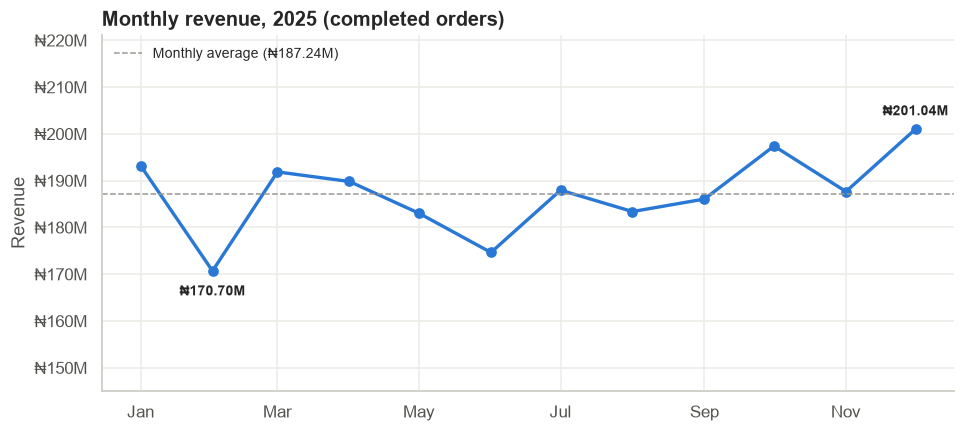

order_month,2025-01-01,2025-02-01,2025-03-01,2025-04-01,2025-05-01,2025-06-01,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01
revenue,"193,227,918.60","170,700,588.45","191,870,551.60","189,823,299.40","183,029,362.70","174,649,129.65","187,964,797.10","183,394,826.35","186,066,857.70","197,402,636.60","187,669,121.60","201,038,740.75"


In [36]:
completed["order_month"] = completed["order_date"].dt.to_period("M")
monthly = completed.groupby("order_month")["net_sales"].sum()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(monthly.index, monthly.values, color=PRIMARY, linewidth=2.2, marker="o", markersize=6)
ax.axhline(monthly.mean(), color=MUTED, linestyle="--", linewidth=1,
           label=f"Monthly average ({naira(monthly.mean())})")
ax.legend(loc="upper left", frameon=False, fontsize=9)
for idx in (monthly.idxmax(), monthly.idxmin()):
    ax.annotate(naira(monthly[idx]), (idx, monthly[idx]), textcoords="offset points",
                xytext=(0, 9 if idx == monthly.idxmax() else -16), ha="center", fontsize=9, fontweight="bold")
ax.yaxis.set_major_formatter(NAIRA_AXIS)
ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%b"))
ax.set_ylim(monthly.min() * 0.85, monthly.max() * 1.1)
ax.set_title("Monthly revenue, 2025 (completed orders)")
ax.set_ylabel("Revenue")
save_fig(fig, "01_monthly_sales_trend")
monthly.to_frame("revenue").T

### 5.2 Revenue by category

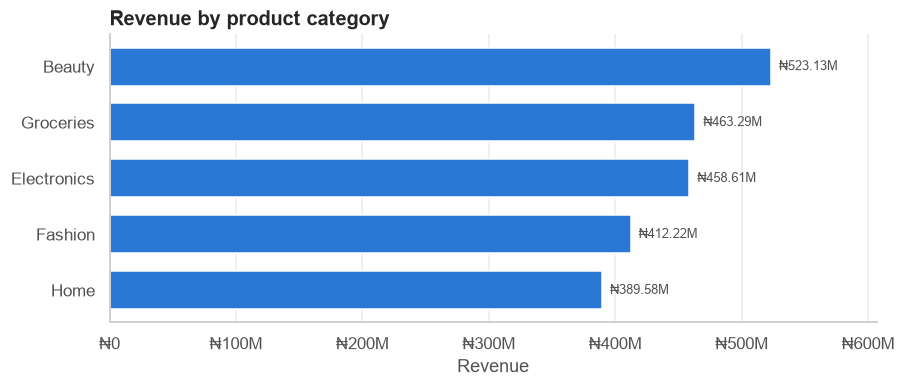

,share
category,
Beauty,23.3%
Groceries,20.6%
Electronics,20.4%
Fashion,18.3%
Home,17.3%


In [37]:
cat_rev = completed.groupby("category", observed=True)["net_sales"].sum()
fig, ax = plt.subplots(figsize=(9, 3.4))
barh_ranked(cat_rev, "Revenue by product category", ax=ax)
save_fig(fig, "02_revenue_by_category")
(cat_rev / cat_rev.sum()).sort_values(ascending=False).to_frame("share").style.format("{:.1%}")

### 5.3 Revenue by store

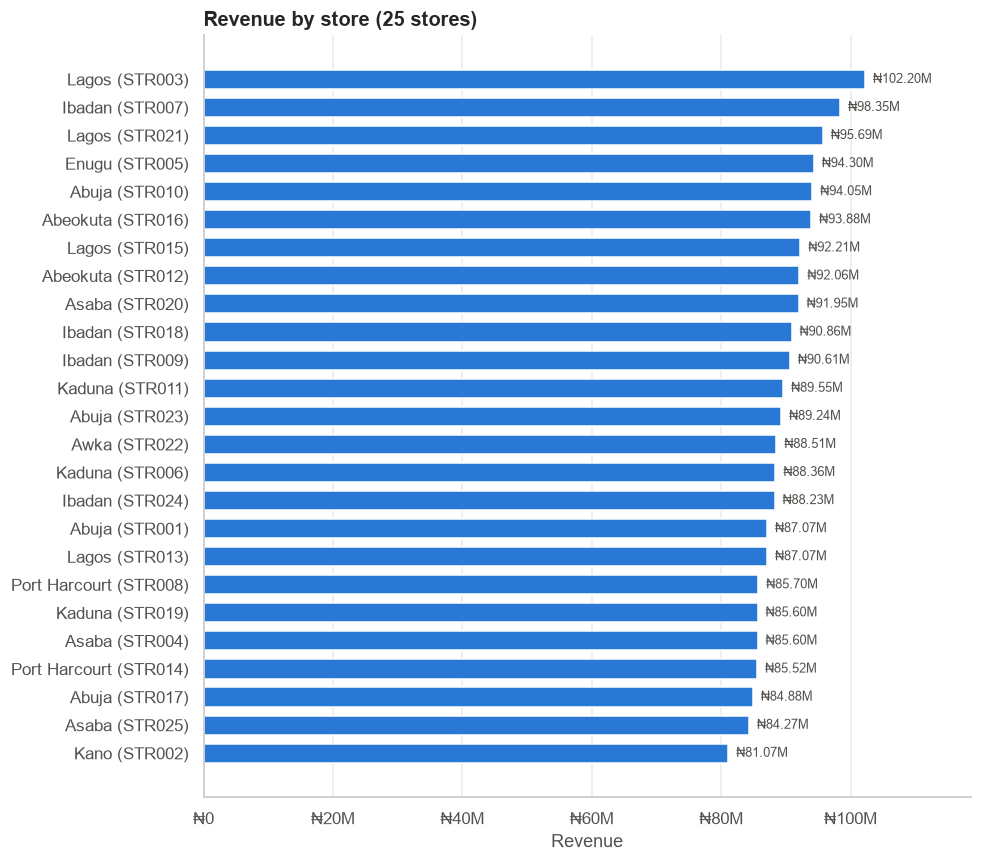

Best store : Lagos (STR003)  ₦102.20M
Worst store: Kano (STR002)  ₦81.07M
Gap between best and worst: 26.1%


In [38]:
store_rev = completed.groupby("store_label")["net_sales"].sum()
fig, ax = plt.subplots(figsize=(9, 9))
barh_ranked(store_rev, "Revenue by store (25 stores)", ax=ax)
save_fig(fig, "03_revenue_by_store")
print(f"Best store : {store_rev.idxmax()}  {naira(store_rev.max())}")
print(f"Worst store: {store_rev.idxmin()}  {naira(store_rev.min())}")
print(f"Gap between best and worst: {store_rev.max() / store_rev.min() - 1:.1%}")

### 5.4 Revenue by state (store location)

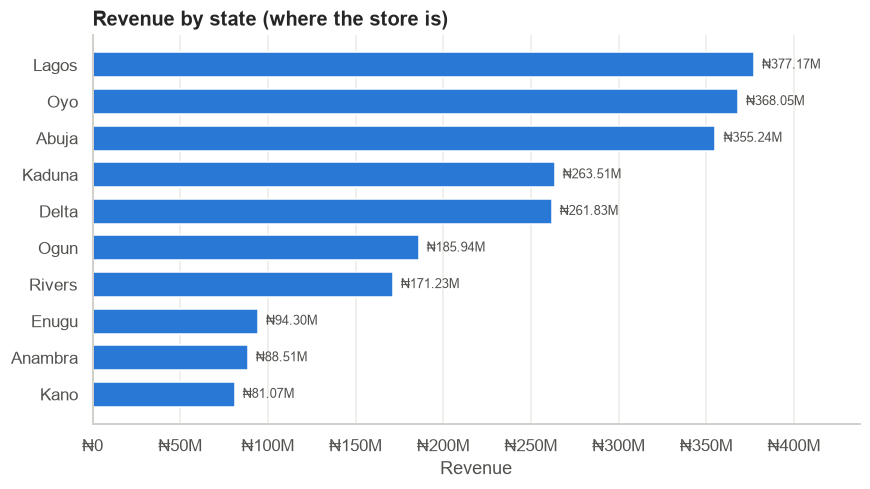

,revenue,stores,revenue_per_store
Lagos,"377,167,421.00",4,"94,291,855.25"
Oyo,"368,049,670.15",4,"92,012,417.54"
Abuja,"355,241,789.15",4,"88,810,447.29"
Kaduna,"263,507,622.30",3,"87,835,874.10"
Delta,"261,827,264.45",3,"87,275,754.82"
Ogun,"185,941,833.80",2,"92,970,916.90"
Rivers,"171,228,141.90",2,"85,614,070.95"
Enugu,"94,301,730.90",1,"94,301,730.90"
Anambra,"88,505,388.60",1,"88,505,388.60"
Kano,"81,066,968.25",1,"81,066,968.25"


In [39]:
state_rev = completed.groupby("store_state", observed=True)["net_sales"].sum()
stores_per_state = clean["stores"].groupby("state", observed=True).size()
fig, ax = plt.subplots(figsize=(9, 4.6))
barh_ranked(state_rev, "Revenue by state (where the store is)", ax=ax)
save_fig(fig, "04_revenue_by_state")
pd.DataFrame({"revenue": state_rev, "stores": stores_per_state,
              "revenue_per_store": state_rev / stores_per_state}).sort_values("revenue", ascending=False)

### 5.5 Top 10 and 5.6 Bottom 10 products

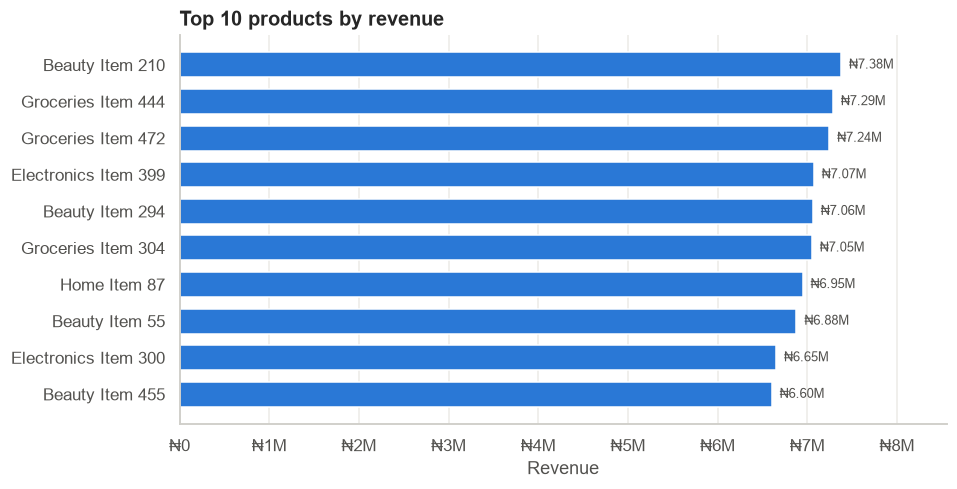

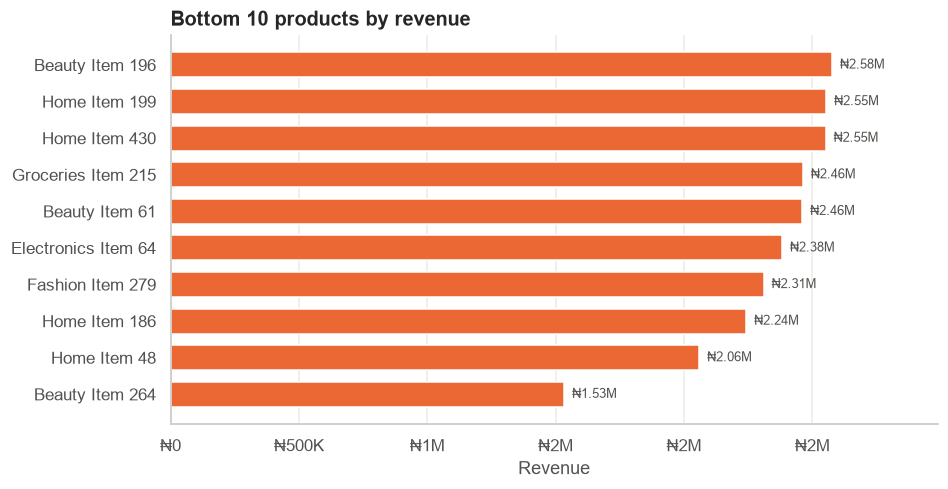

Top-10 products earn 3.1% of revenue (500 products sold).


In [40]:
product_rev = completed.groupby("product_name")["net_sales"].sum()
top10, bottom10 = product_rev.nlargest(10), product_rev.nsmallest(10)

fig, ax = plt.subplots(figsize=(9, 4.6))
barh_ranked(top10, "Top 10 products by revenue", ax=ax)
save_fig(fig, "05_top10_products")

fig, ax = plt.subplots(figsize=(9, 4.6))
barh_ranked(bottom10, "Bottom 10 products by revenue", ax=ax, color=ACCENT)
save_fig(fig, "06_bottom10_products")

print(f"Top-10 products earn {top10.sum() / product_rev.sum():.1%} of revenue "
      f"({len(product_rev)} products sold).")

### 5.7 Customer age distribution

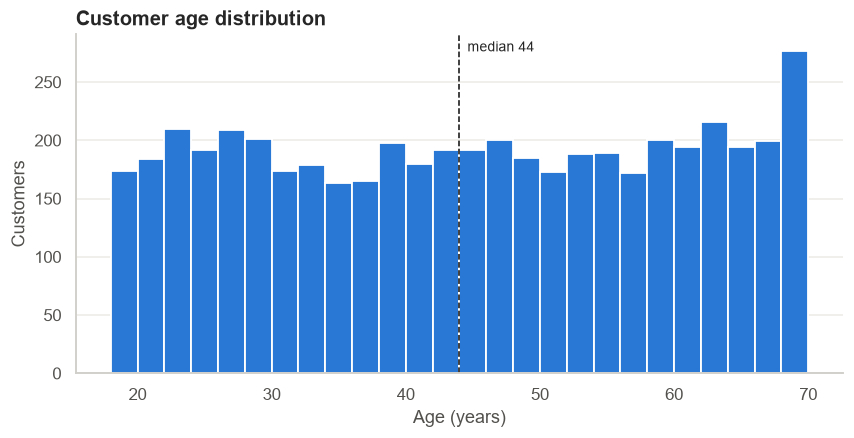

In [41]:
ages = clean["customers"]["age"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(ages, bins=range(18, 72, 2), color=PRIMARY, edgecolor="white", linewidth=1.2)
ax.axvline(ages.median(), color="#0b0b0b", linestyle="--", linewidth=1)
ax.text(ages.median(), ax.get_ylim()[1] * 0.95, f"  median {ages.median():.0f}", fontsize=9)
ax.set_title("Customer age distribution")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Customers")
ax.grid(axis="x", visible=False)
save_fig(fig, "07_customer_age_distribution")

### 5.8 Product price distribution

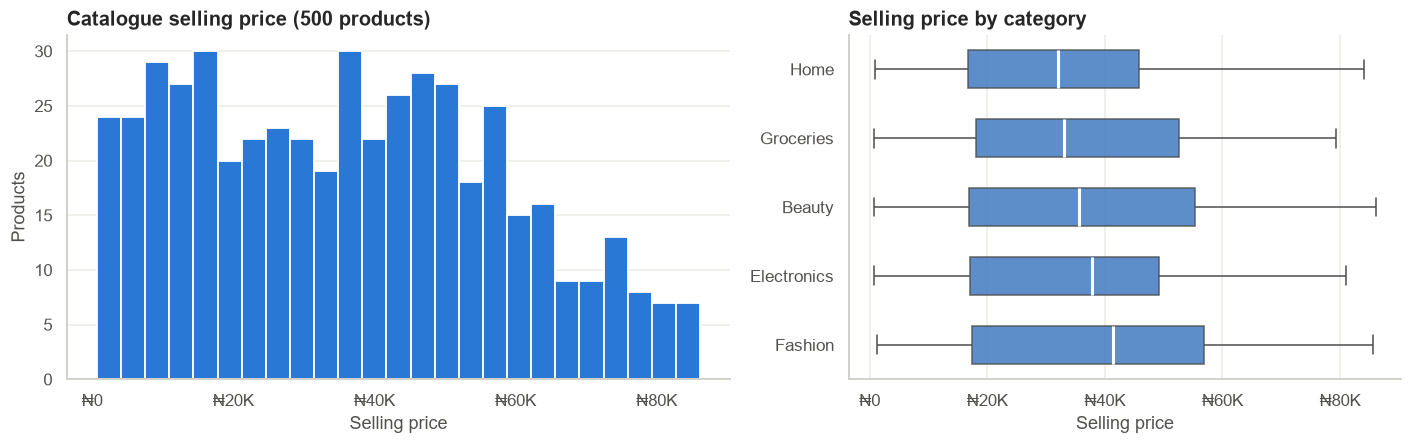

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})
axes[0].hist(clean["products"]["selling_price"], bins=25, color=PRIMARY, edgecolor="white", linewidth=1.2)
axes[0].xaxis.set_major_formatter(NAIRA_AXIS)
axes[0].set_title("Catalogue selling price (500 products)")
axes[0].set_xlabel("Selling price")
axes[0].set_ylabel("Products")
axes[0].grid(axis="x", visible=False)

order_cat = clean["products"].groupby("category", observed=True)["selling_price"].median().sort_values().index
sns.boxplot(data=clean["products"], y="category", x="selling_price", order=order_cat, ax=axes[1],
            color=PRIMARY, width=0.55, linewidth=1, fliersize=3,
            boxprops={"alpha": 0.85}, medianprops={"color": "white", "linewidth": 2})
axes[1].xaxis.set_major_formatter(NAIRA_AXIS)
axes[1].set_title("Selling price by category")
axes[1].set_xlabel("Selling price")
axes[1].set_ylabel("")
fig.tight_layout()
save_fig(fig, "08_product_price_distribution")

### 5.9 Return rate by category

Return rate = returned orders ÷ all orders in the category. The denominator includes every status,
because returns are recorded against orders of every status (Part 3f).

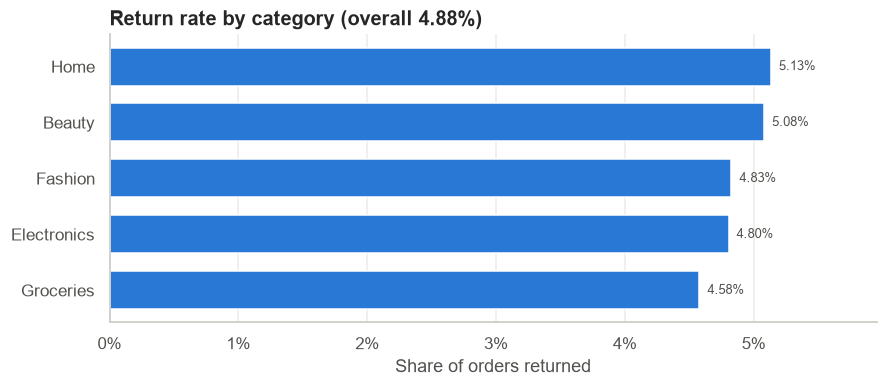

,orders,returned,return_rate
category,,,
Home,8610,442,0.05
Beauty,11809,600,0.05
Fashion,9260,447,0.05
Electronics,9969,479,0.05
Groceries,10352,474,0.05


In [43]:
cat_returns = sales.groupby("category", observed=True).agg(orders=("order_id", "count"),
                                                            returned=("is_returned", "sum"))
cat_returns["return_rate"] = cat_returns["returned"] / cat_returns["orders"]
fig, ax = plt.subplots(figsize=(9, 3.4))
barh_ranked(cat_returns["return_rate"], f"Return rate by category (overall {sales['is_returned'].mean():.2%})",
            xlabel="Share of orders returned", pct=True, ax=ax, label_fmt=lambda v: f"{v:.2%}")
save_fig(fig, "09_return_rate_by_category")
cat_returns.sort_values("return_rate", ascending=False)

### 5.10 Inventory by store

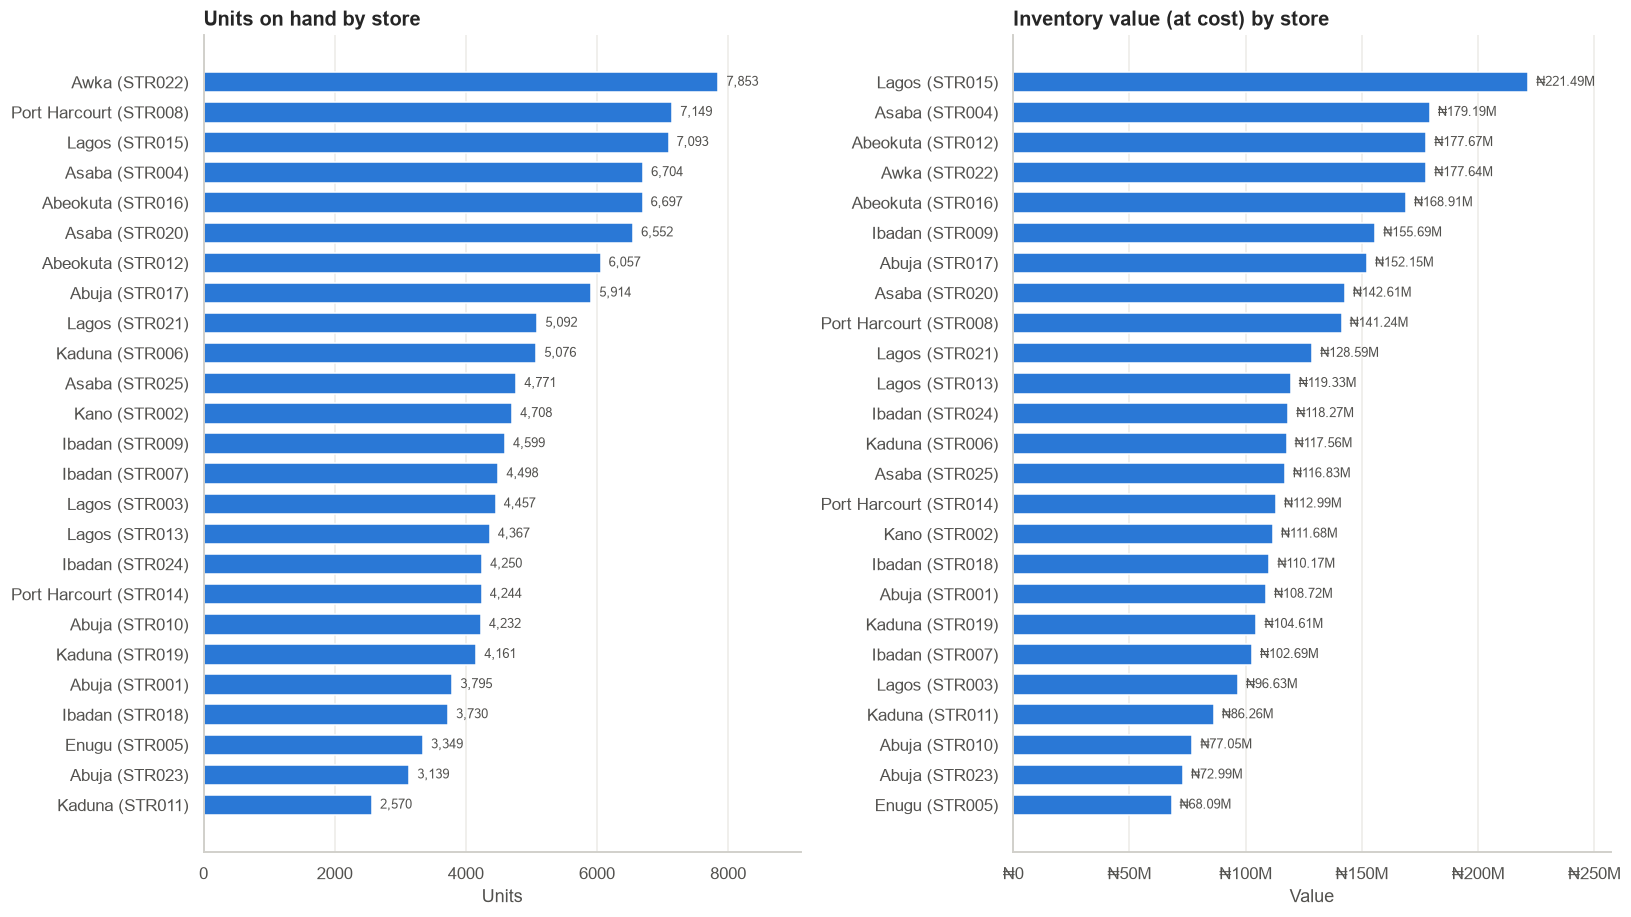

,products,units,stock_value
store_label,,,
Lagos (STR015),25,7093,221485649
Asaba (STR004),24,6704,179192496
Abeokuta (STR012),20,6057,177665975
Awka (STR022),25,7853,177637412
Abeokuta (STR016),24,6697,168913098


In [44]:
inventory = clean["inventory"].merge(clean["products"][["product_id", "product_name", "category", "cost_price"]],
                                     on="product_id").merge(clean["stores"][["store_id", "store_label", "geo_zone"]],
                                                            on="store_id")
inventory["stock_value"] = inventory["stock_on_hand"] * inventory["cost_price"]
inv_store = inventory.groupby("store_label").agg(products=("product_id", "count"),
                                                 units=("stock_on_hand", "sum"),
                                                 stock_value=("stock_value", "sum"))

fig, axes = plt.subplots(1, 2, figsize=(15, 8.5), sharey=False)
barh_ranked(inv_store["units"], "Units on hand by store", xlabel="Units", money=False, ax=axes[0])
barh_ranked(inv_store["stock_value"], "Inventory value (at cost) by store", xlabel="Value", ax=axes[1])
fig.tight_layout()
save_fig(fig, "10_inventory_by_store")
inv_store.sort_values("stock_value", ascending=False).head()

### 5.11 What the charts show

| Chart | Observation |
|-------|-------------|
| Monthly trend | Revenue is fairly **flat** at ₦171M–₦201M a month. **December (₦201M) and October (₦197M)** are the peaks. February is the lowest, but mostly because it has 28 days, since its revenue per day (₦6.1M) is close to average. Q4 is the strongest quarter. |
| Category | **Beauty leads with 23%** of revenue, then Groceries (21%) and Electronics (20%). Revenue *per product* is almost identical across categories (₦4.4M–₦4.6M), so Beauty leads because it has the **most products** (119), not because each product sells better. |
| Store | The best store, **Lagos (STR003), earns ₦102M** and the weakest, **Kano (STR002), earns ₦81M**: a 26% gap. Most stores sit in a narrow ₦85M–₦95M band. |
| State | Lagos, Oyo and Abuja lead in total revenue only because they have the most stores (4 each). **Per store, Enugu and Lagos lead (about ₦94M) and Kano trails (₦81M).** |
| Top/Bottom 10 | Revenue is spread very evenly. The top 10 products make only **3.1%** of revenue, so no single product is critical. The bottom 10 earn very little and are candidates for review. |
| Age | Customers are spread **evenly from 18 to 70** (median 44), with no dominant age group. |
| Price | Catalogue prices range from ₦676 to ₦86K, skewed towards cheaper items. Price ranges overlap heavily across categories. |
| Return rate | Returns are **4.6%–5.1% in every category**. Home and Beauty are slightly higher and Groceries lowest. The differences are small. |
| Inventory | Stock is **unevenly spread**. Lagos (STR015) holds ₦221M at cost, more than 3× Enugu (STR005, ₦68M), even though Enugu is one of the best-selling stores. |

## Part 6: Correlation analysis

The analysis looks at relationships at two levels:

1. **Order line:** what drives the value and the return of a single order?
2. **Customer:** how do age, frequency and spending relate?

Pearson correlation measures *linear* relationships. Values near ±1 are strong and values near 0
show no linear link.

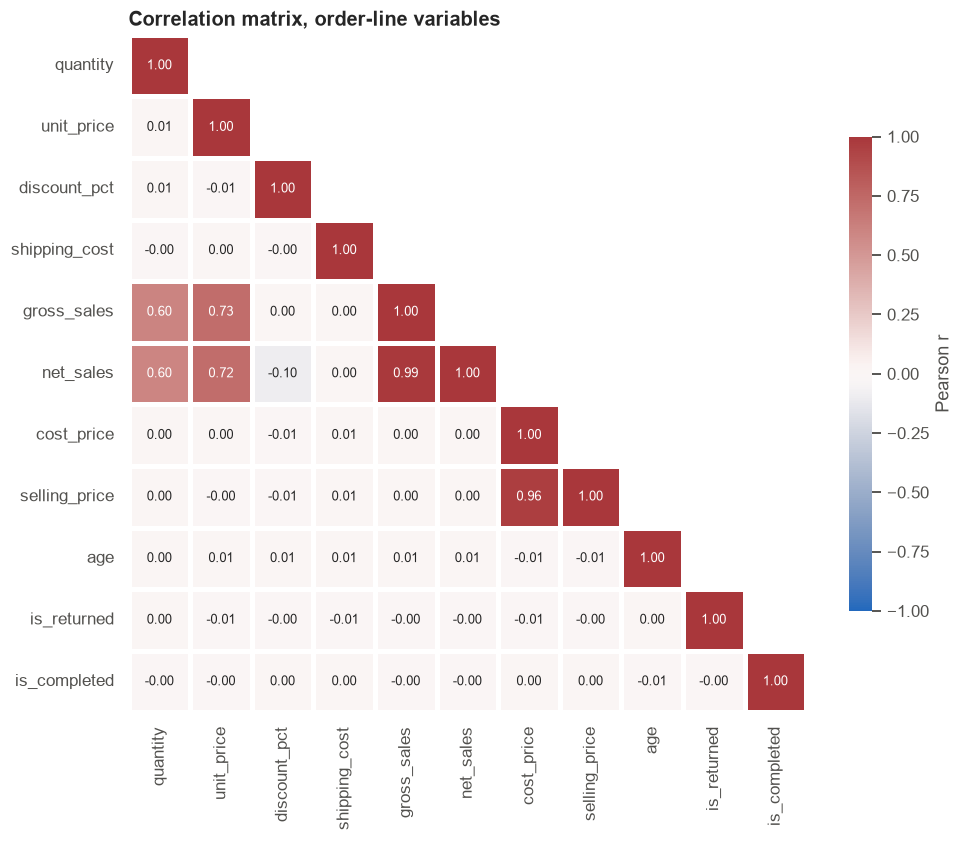

In [45]:
ORDER_NUMERIC = ["quantity", "unit_price", "discount_pct", "shipping_cost", "gross_sales",
                 "net_sales", "cost_price", "selling_price", "age", "is_returned", "is_completed"]
order_corr = sales[ORDER_NUMERIC].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(order_corr, dtype=bool), k=1)
sns.heatmap(order_corr, mask=mask, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0,
            square=True, linewidths=2, linecolor="white", cbar_kws={"shrink": 0.7, "label": "Pearson r"},
            annot_kws={"size": 8.5}, ax=ax)
ax.set_title("Correlation matrix, order-line variables")
ax.grid(False)
save_fig(fig, "11_correlation_heatmap_orders")

In [46]:
def strongest_pairs(corr: pd.DataFrame, n: int = 8) -> pd.DataFrame:
    """List the variable pairs with the largest absolute correlation."""
    pairs = corr.where(np.triu(np.ones_like(corr, dtype=bool), k=1)).stack()
    return (pairs.rename("r").reset_index().rename(columns={"level_0": "var_1", "level_1": "var_2"})
            .assign(abs_r=lambda d: d["r"].abs()).sort_values("abs_r", ascending=False).head(n))


strongest_pairs(order_corr)

,var_1,var_2,r,abs_r
49,gross_sales,net_sales,0.99,0.99
73,cost_price,selling_price,0.96,0.96
15,unit_price,gross_sales,0.73,0.73
16,unit_price,net_sales,0.72,0.72
4,quantity,gross_sales,0.60,0.60
5,quantity,net_sales,0.60,0.60
27,discount_pct,net_sales,-0.10,0.10
40,shipping_cost,selling_price,0.01,0.01


### 6.1 Customer-level correlation

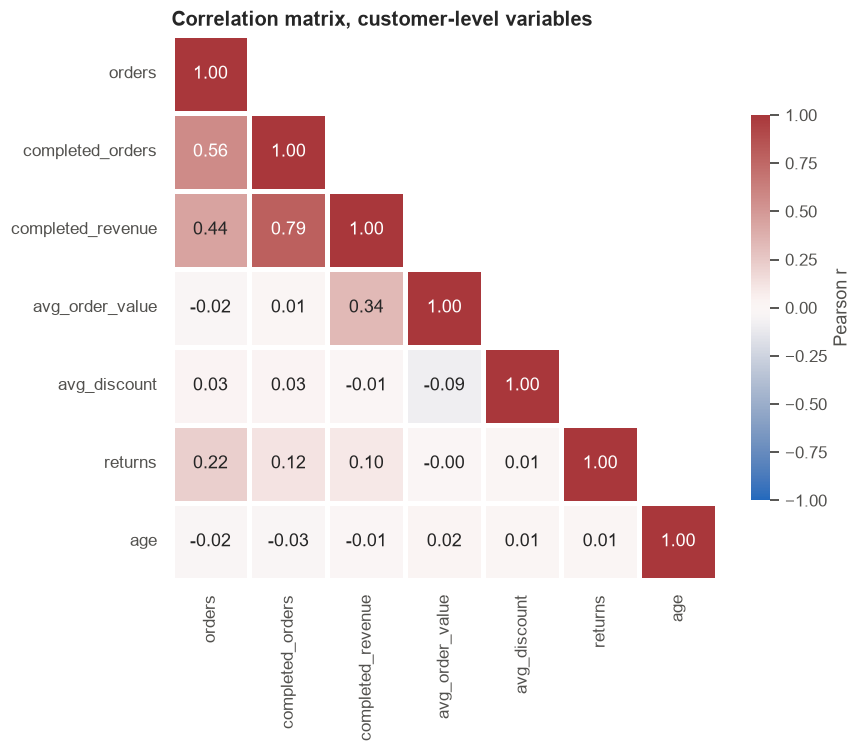

,var_1,var_2,r,abs_r
9,completed_orders,completed_revenue,0.79,0.79
1,orders,completed_orders,0.56,0.56
2,orders,completed_revenue,0.44,0.44
17,completed_revenue,avg_order_value,0.34,0.34
5,orders,returns,0.22,0.22
12,completed_orders,returns,0.12,0.12


In [47]:
customer_level = (
    sales.assign(completed_revenue=sales["net_sales"] * sales["is_completed"])
    .groupby("customer_id")
    .agg(orders=("order_id", "count"), completed_orders=("is_completed", "sum"),
         completed_revenue=("completed_revenue", "sum"),
         avg_order_value=("net_sales", "mean"), avg_discount=("discount_pct", "mean"),
         returns=("is_returned", "sum"))
    .join(clean["customers"].set_index("customer_id")[["age"]])
)
customer_corr = customer_level.corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(customer_corr, mask=np.triu(np.ones_like(customer_corr, dtype=bool), k=1), annot=True, fmt=".2f",
            cmap="vlag", vmin=-1, vmax=1, center=0, square=True, linewidths=2, linecolor="white",
            cbar_kws={"shrink": 0.7, "label": "Pearson r"}, ax=ax)
ax.set_title("Correlation matrix, customer-level variables")
ax.grid(False)
save_fig(fig, "12_correlation_heatmap_customers")
strongest_pairs(customer_corr, 6)

### 6.2 Pair plot (selected numerical features)

The pair plot uses a random sample of 2,000 order lines, so the points stay readable and the
chart renders quickly.

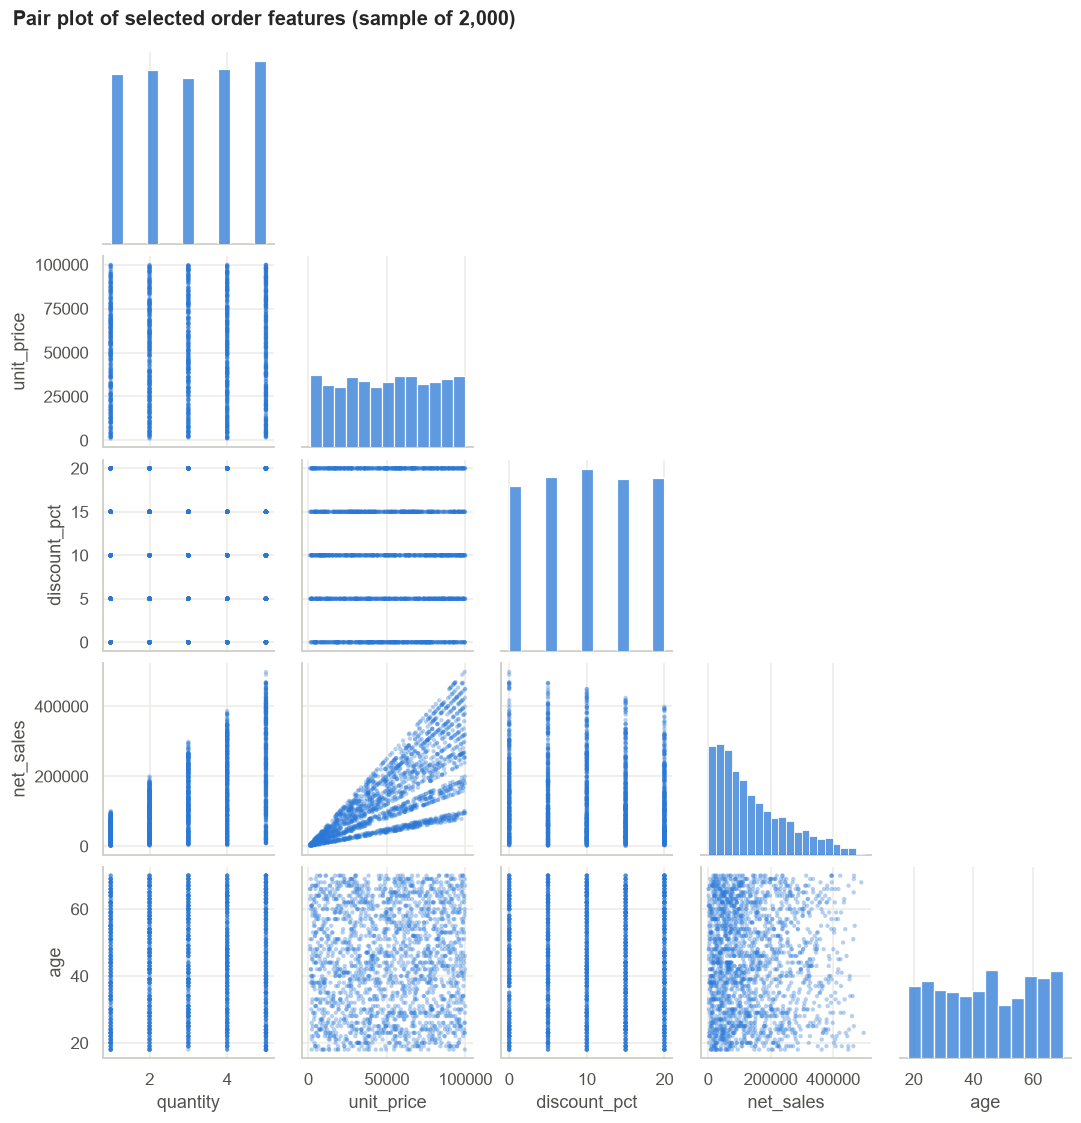

In [48]:
pair_sample = sales.sample(2000, random_state=42)[["quantity", "unit_price", "discount_pct", "net_sales", "age"]]
grid = sns.pairplot(pair_sample, corner=True, height=2.0,
                    plot_kws={"s": 8, "alpha": 0.35, "color": PRIMARY, "edgecolor": "none"},
                    diag_kws={"color": PRIMARY, "edgecolor": "white"})
grid.figure.suptitle("Pair plot of selected order features (sample of 2,000)", x=0.02, ha="left",
                     y=1.02, fontsize=13, fontweight="bold")
save_fig(grid.figure, "13_pair_plot")

### 6.3 Interpretation

**Strongly correlated**

* `gross_sales` and `net_sales` (r = 0.99): net is gross minus a discount of at most 20%.
* `cost_price` and `selling_price` (r = 0.96): the catalogue applies a consistent markup over cost.
* `unit_price` and `net_sales` (r = 0.72) and `quantity` and `net_sales` (r = 0.60): order value is
  price × quantity, and price has slightly more influence.
* Customer level: `completed_orders` and `completed_revenue` (r = 0.79). Customers who complete more
  orders spend more in total. **Frequency drives customer value**, more than average order value (r = 0.34).
* `orders` and `returns` (r = 0.22): customers who order more also return more, simply because they
  have more chances to.

**Unrelated (|r| < 0.05)**

* `discount_pct` has no link with quantity or price. Discounts do not appear to make people buy more,
  so they may be giving margin away. Its weak negative link with `net_sales` (r = −0.10) is just the
  arithmetic of the discount.
* `age` is unrelated to everything: order value, frequency and returns.
* `shipping_cost` is unrelated to order value, so it does not scale with the size of the basket.
* `is_returned` is unrelated to every numeric variable, including price, discount and quantity.
* `unit_price` (the price actually paid) is barely related to the catalogue `selling_price` or
  `cost_price`. This confirms the pricing inconsistency from Part 3(g).

**Why this matters for modelling**

* **Leakage and redundancy:** `gross_sales`, `net_sales` and `quantity × unit_price` carry the same
  information. A model that predicts order value must not use them as inputs, and only one should be
  kept as a feature.
* **Return prediction will be hard** with the current variables, because none correlate with returns.
  Better signals (product reviews, delivery times, customer return history) need to be collected.
* **Customer value models** should focus on **purchase frequency and recency** rather than demographics.
* **Discount strategy:** discounts do not lift volume, which is worth testing with a controlled experiment.

## Part 7: Feature engineering

New features are built at the level where they make sense: **order line**, **customer** and
**inventory item**. Each one comes with a short note on why it could help a future model.

In [49]:
REFERENCE_DATE = sales["order_date"].max() + pd.Timedelta(days=1)   # 2026-01-01, the day after the data ends
AGE_BINS = [17, 24, 34, 44, 54, 64, 120]
AGE_LABELS = ["18-24", "25-34", "35-44", "45-54", "55-64", "65+"]


def add_order_features(df: pd.DataFrame) -> pd.DataFrame:
    """Profitability, discount and calendar features for each order line."""
    df = df.copy()
    df["cost_of_goods"] = df["quantity"] * df["cost_price"]
    df["profit"] = df["net_sales"] - df["cost_of_goods"]
    df["profit_margin"] = df["profit"] / df["net_sales"]
    df["below_cost"] = (df["profit"] < 0).astype(int)
    df["discount_percentage"] = df["discount_amount"] / df["gross_sales"]   # as a 0-1 share
    df["order_month"] = df["order_date"].dt.month
    df["order_month_name"] = df["order_date"].dt.strftime("%b")
    df["order_quarter"] = "Q" + df["order_date"].dt.quarter.astype(str)
    df["order_day_of_week"] = df["order_date"].dt.day_name()
    df["is_weekend"] = df["order_date"].dt.dayofweek.ge(5).astype(int)
    df["customer_age_group"] = pd.cut(df["age"], bins=AGE_BINS, labels=AGE_LABELS)
    return df


sales_fe = add_order_features(sales)
sales_fe[["order_id", "net_sales", "cost_of_goods", "profit", "profit_margin", "below_cost",
          "discount_percentage", "order_month", "order_quarter", "customer_age_group"]].head()

,order_id,net_sales,cost_of_goods,profit,profit_margin,below_cost,discount_percentage,order_month,order_quarter,customer_age_group
0,ORD000001,"70,190.10",48631,"21,559.10",0.31,0,0.10,7,Q3,65+
1,ORD000002,"32,034.00",9807,"22,227.00",0.69,0,0.05,3,Q1,65+
2,ORD000003,"37,752.00",62054,"-24,302.00",-0.64,1,0.20,10,Q4,18-24
3,ORD000004,"265,703.60",116856,"148,847.60",0.56,0,0.05,7,Q3,55-64
4,ORD000005,"266,720.00",176120,"90,600.00",0.34,0,0.00,3,Q1,35-44


In [50]:
def build_customer_features(df: pd.DataFrame, customers: pd.DataFrame,
                            lifespan_years: float = 3.0) -> pd.DataFrame:
    """Customer-level RFM-style features and an approximate Customer Lifetime Value (CLV).

    CLV ≈ average completed order value × completed orders per year × gross margin × expected lifespan.
    The data covers exactly one year, so completed orders in 2025 = purchase frequency per year.
    `lifespan_years` is an assumption (3 years) and should be calibrated once churn data exists.
    """
    done = df[df["is_completed"] == 1]
    agg = done.groupby("customer_id").agg(
        completed_orders=("order_id", "count"),
        total_revenue=("net_sales", "sum"),
        total_profit=("profit", "sum"),
        avg_order_value=("net_sales", "mean"),
    )
    activity = df.groupby("customer_id").agg(
        total_orders=("order_id", "count"),
        last_order_date=("order_date", "max"),
        returns=("is_returned", "sum"),
        avg_discount_pct=("discount_pct", "mean"),
    )
    feats = customers.set_index("customer_id")[["customer_segment", "gender", "age", "state", "registration_date"]] \
        .join(activity).join(agg).fillna({"completed_orders": 0, "total_revenue": 0, "total_profit": 0,
                                          "avg_order_value": 0})
    feats["customer_age_group"] = pd.cut(feats["age"], bins=AGE_BINS, labels=AGE_LABELS)
    feats["days_since_last_purchase"] = (REFERENCE_DATE - feats["last_order_date"]).dt.days
    feats["tenure_days"] = (REFERENCE_DATE - feats["registration_date"]).dt.days
    feats["completion_rate"] = feats["completed_orders"] / feats["total_orders"]
    feats["return_rate"] = feats["returns"] / feats["total_orders"]
    margin = (feats["total_profit"] / feats["total_revenue"]).where(feats["total_revenue"] > 0, 0).clip(lower=0)
    feats["clv_estimate"] = feats["avg_order_value"] * feats["completed_orders"] * margin * lifespan_years
    return feats


customer_features = build_customer_features(sales_fe, clean["customers"])
customer_features[["customer_segment", "customer_age_group", "completed_orders", "total_revenue",
                   "avg_order_value", "days_since_last_purchase", "clv_estimate"]].head()

,customer_segment,customer_age_group,completed_orders,total_revenue,avg_order_value,days_since_last_purchase,clv_estimate
customer_id,,,,,,,
CUST00001,Bronze,65+,3.00,"346,080.00","115,360.00",8,"602,595.00"
CUST00002,Gold,65+,3.00,"488,458.10","162,819.37",82,"1,199,007.30"
CUST00003,Bronze,55-64,4.00,"336,050.40","84,012.60",32,"324,220.20"
CUST00004,Gold,25-34,7.00,"876,116.50","125,159.50",3,"1,296,214.50"
CUST00005,Gold,45-54,4.00,"396,895.25","99,223.81",51,"227,997.75"


In [51]:
def build_inventory_features(inv: pd.DataFrame, df: pd.DataFrame) -> pd.DataFrame:
    """Stock cover and Low/Medium/High status for each inventory record.

    stock_cover = stock_on_hand / reorder_level
      Low    : at or below the reorder level (cover <= 1), restock now
      Medium : up to 3x the reorder level, monitor
      High   : more than 3x the reorder level, possibly overstocked
    Days of supply uses the product's 2025 completed unit sales across all stores.
    """
    inv = inv.copy()
    inv["stock_cover"] = inv["stock_on_hand"] / inv["reorder_level"]
    inv["inventory_status"] = pd.cut(inv["stock_cover"], bins=[0, 1, 3, np.inf], labels=["Low", "Medium", "High"])
    daily_units = df[df["is_completed"] == 1].groupby("product_id")["quantity"].sum() / 365
    inv["avg_daily_units_sold"] = inv["product_id"].map(daily_units).fillna(0)
    inv["days_of_supply"] = inv["stock_on_hand"] / inv["avg_daily_units_sold"].replace(0, np.nan)
    return inv


inventory_features = build_inventory_features(inventory, sales_fe)
inventory_features["inventory_status"].value_counts().reindex(["Low", "Medium", "High"]).to_frame("items")

,items
inventory_status,
Low,21
Medium,62
High,417


### 7.1 Quick look at the new features

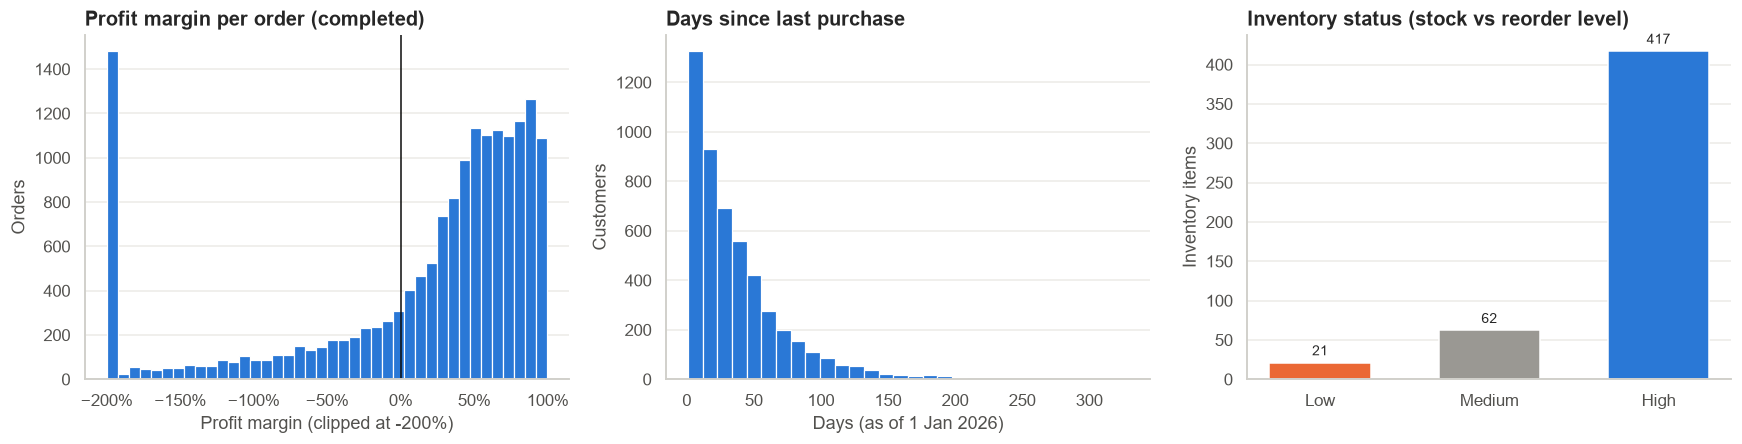

Overall gross margin (completed): 44.7%
Completed order lines sold below cost: 27.3% (loss ₦225,719,588)
Median days since last purchase: 26
Median CLV estimate: ₦482,596


In [52]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

axes[0].hist(sales_fe.loc[sales_fe["is_completed"] == 1, "profit_margin"].clip(-2, 1), bins=40,
             color=PRIMARY, edgecolor="white", linewidth=0.8)
axes[0].axvline(0, color="#0b0b0b", linewidth=1)
axes[0].set_title("Profit margin per order (completed)")
axes[0].set_xlabel("Profit margin (clipped at -200%)")
axes[0].xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[0].set_ylabel("Orders")

axes[1].hist(customer_features["days_since_last_purchase"], bins=30, color=PRIMARY, edgecolor="white", linewidth=0.8)
axes[1].set_title("Days since last purchase")
axes[1].set_xlabel("Days (as of 1 Jan 2026)")
axes[1].set_ylabel("Customers")

status_counts = inventory_features["inventory_status"].value_counts().reindex(["Low", "Medium", "High"])
bars = axes[2].bar(status_counts.index.astype(str), status_counts.values, color=[ACCENT, MUTED, PRIMARY], width=0.6)
axes[2].bar_label(bars, padding=3, fontsize=9)
axes[2].set_title("Inventory status (stock vs reorder level)")
axes[2].set_ylabel("Inventory items")
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.tight_layout()
save_fig(fig, "14_engineered_features")

done_fe = sales_fe[sales_fe["is_completed"] == 1]
print(f"Overall gross margin (completed): {done_fe['profit'].sum() / done_fe['net_sales'].sum():.1%}")
print(f"Completed order lines sold below cost: {done_fe['below_cost'].mean():.1%} "
      f"(loss ₦{-done_fe.loc[done_fe['profit'] < 0, 'profit'].sum():,.0f})")
print(f"Median days since last purchase: {customer_features['days_since_last_purchase'].median():.0f}")
print(f"Median CLV estimate: ₦{customer_features['clv_estimate'].median():,.0f}")

**Reading the feature charts**

* **Profit margin:** completed orders earn an overall gross margin of about **45%**, but **27% of
  completed order lines lose money**, about **₦226M** in 2025. The spike at −200% gathers every order
  that lost more than twice its sale value (the axis is clipped there). Those are deep below-cost sales.
* **Recency:** half of customers bought within the last ~26 days of 2025. A long tail of customers
  has been inactive for 100+ days, and they are the first targets for a churn model.
* **Inventory:** only **21 items are Low** while **417 are High**. Overstock is a much bigger problem than stock-outs.

In [53]:
# Save engineered datasets for the ML track
sales_fe.to_csv(CLEAN_DIR / "sales_features.csv", index=False)
customer_features.to_csv(CLEAN_DIR / "customer_features.csv")
inventory_features.to_csv(CLEAN_DIR / "inventory_features.csv", index=False)

### 7.2 Why each feature helps future models

| Feature | Level | Why it may improve models |
|---------|-------|----------------------------|
| **Profit margin** (+ `profit`, `below_cost`) | Order | Revenue alone hides loss-making sales. Margin lets models optimise for *profit*, and `below_cost` is a ready-made target for detecting pricing errors. |
| **Order month** | Order | Captures seasonality (the Q4 / December peak) for sales forecasting. |
| **Order quarter** | Order | A coarser seasonal signal that is less noisy for small categories or stores. |
| **Customer age group** | Order / Customer | Groups a continuous variable into segments marketing can act on, and lets tree models find non-linear age effects. |
| **Customer Lifetime Value (approx.)** | Customer | Ranks customers by expected long-term worth, for prioritising retention and setting acquisition budgets. It is also a target for CLV regression. |
| **Discount percentage** | Order | Puts discounts on one 0–1 scale, which is needed to measure price elasticity and whether promotions pay off. |
| **Days since last purchase** | Customer | *Recency* is the strongest single predictor of churn in retail and is the "R" in RFM segmentation. |
| **Inventory status (Low/Medium/High)** (+ `days_of_supply`) | Inventory | Turns raw stock counts into actions (reorder, monitor, overstocked) and is a label for inventory forecasting and stock-out alerts. |

Also added: `is_weekend`, `order_day_of_week`, `completion_rate`, `return_rate` per customer,
`tenure_days` and `stock_cover`.

## Part 8: Business questions

Each answer is backed by a table or chart. `done_fe` holds the completed order lines with the
Part 7 features (profit, month, quarter and so on).

In [54]:
insights = {}   # key facts collected for the report


def summarise(df: pd.DataFrame, by, all_orders: pd.DataFrame = sales_fe) -> pd.DataFrame:
    """Standard performance table: revenue, profit, orders, AOV, completion and return rate."""
    perf = df.groupby(by, observed=True).agg(revenue=("net_sales", "sum"), profit=("profit", "sum"),
                                             completed_orders=("order_id", "count"),
                                             units=("quantity", "sum"))
    perf["aov"] = perf["revenue"] / perf["completed_orders"]
    perf["margin"] = perf["profit"] / perf["revenue"]
    base = all_orders.groupby(by, observed=True).agg(all_orders=("order_id", "count"),
                                                     completion_rate=("is_completed", "mean"),
                                                     return_rate=("is_returned", "mean"))
    return perf.join(base).sort_values("revenue", ascending=False)


PERF_FMT = {"revenue": "₦{:,.0f}", "profit": "₦{:,.0f}", "aov": "₦{:,.0f}", "margin": "{:.1%}",
            "completion_rate": "{:.1%}", "return_rate": "{:.2%}", "completed_orders": "{:,}",
            "units": "{:,}", "all_orders": "{:,}"}

### Q1. Which products generate the most revenue?

In [55]:
product_perf = summarise(done_fe, ["product_name", "category"])
insights["top_product"] = product_perf.index[0][0]
insights["top_product_revenue"] = float(product_perf["revenue"].iloc[0])
product_perf.head(10).style.format(PERF_FMT)

,,revenue,profit,completed_orders,units,aov,margin,all_orders,completion_rate,return_rate
product_name,category,,,,,,,,,
Beauty Item 210,Beauty,"₦7,375,596","₦2,222,952",45,127,"₦163,902",30.1%,101,44.6%,3.96%
Groceries Item 444,Groceries,"₦7,285,023","₦1,046,183",50,152,"₦145,700",14.4%,128,39.1%,4.69%
Groceries Item 472,Groceries,"₦7,243,501","₦2,502,401",47,140,"₦154,117",34.5%,111,42.3%,6.31%
Electronics Item 399,Electronics,"₦7,071,427","₦2,689,635",46,149,"₦153,727",38.0%,100,46.0%,3.00%
Beauty Item 294,Beauty,"₦7,060,721","₦3,725,501",45,140,"₦156,905",52.8%,112,40.2%,2.68%
Groceries Item 304,Groceries,"₦7,050,031","₦2,627,726",50,155,"₦141,001",37.3%,121,41.3%,6.61%
Home Item 87,Home,"₦6,947,376","₦4,519,046",42,139,"₦165,414",65.0%,110,38.2%,4.55%
Beauty Item 55,Beauty,"₦6,878,310","₦3,518,248",42,137,"₦163,769",51.1%,94,44.7%,2.13%
Electronics Item 300,Electronics,"₦6,651,170","₦1,969,430",42,140,"₦158,361",29.6%,108,38.9%,5.56%


In [56]:
top_by_profit = product_perf.sort_values("profit", ascending=False).head(10)
print("Products in BOTH the top-10 by revenue and the top-10 by profit:",
      sorted(set(product_perf.head(10).index) & set(top_by_profit.index)))
print(f"Products making an overall loss in 2025: {(product_perf['profit'] < 0).sum()} of {len(product_perf)}")

Products in BOTH the top-10 by revenue and the top-10 by profit: []
Products making an overall loss in 2025: 57 of 500


**Answer:** **Beauty Item 210** (₦7.38M) generates the most revenue, followed by Groceries Items 444
and 472. The top 10 all earn ₦6.6M–₦7.4M, and together they make only about 3% of revenue, so no
single product is critical.

**Revenue leaders are not profit leaders.** None of the top 10 products by revenue is in the top 10
by profit. Groceries Item 444, for example, earns ₦7.3M at only a 14% margin, while the most
profitable products earn 93–99% margins. **57 of 500 products lost money overall in 2025.**
Product decisions should be based on profit, not revenue.

### Q2. Which stores perform best?

In [57]:
store_perf = summarise(done_fe, "store_label")
insights["best_store"] = store_perf.index[0]
insights["best_store_revenue"] = float(store_perf["revenue"].iloc[0])
insights["worst_store"] = store_perf.index[-1]
insights["worst_store_revenue"] = float(store_perf["revenue"].iloc[-1])
pd.concat([store_perf.head(5), store_perf.tail(3)]).style.format(PERF_FMT)

,revenue,profit,completed_orders,units,aov,margin,all_orders,completion_rate,return_rate
store_label,,,,,,,,,
Lagos (STR003),"₦102,203,163","₦47,991,235",715,"2,170","₦142,941",47.0%,"1,970",36.3%,5.33%
Ibadan (STR007),"₦98,354,921","₦46,652,365",668,"2,038","₦147,238",47.4%,"1,978",33.8%,3.79%
Lagos (STR021),"₦95,690,462","₦43,025,251",699,"2,098","₦136,896",45.0%,"2,030",34.4%,4.73%
Enugu (STR005),"₦94,301,731","₦41,782,977",681,"2,062","₦138,475",44.3%,"2,032",33.5%,4.63%
Abuja (STR010),"₦94,054,524","₦44,176,171",680,"2,025","₦138,315",47.0%,"2,052",33.1%,5.31%
Abuja (STR017),"₦84,878,345","₦37,044,300",623,"1,861","₦136,241",43.6%,"2,012",31.0%,4.72%
Asaba (STR025),"₦84,274,065","₦40,170,512",641,"1,847","₦131,473",47.7%,"2,009",31.9%,5.43%
Kano (STR002),"₦81,066,968","₦35,554,304",632,"1,864","₦128,271",43.9%,"2,001",31.6%,4.70%


**Answer:** **Lagos (STR003)** is the best store, with ₦102M revenue and ₦48M profit. It is followed
by **Ibadan (STR007)** and **Lagos (STR021)**. **Kano (STR002)** is the weakest at ₦81M.

Every store receives about **2,000 orders**. The difference is how many of those orders are
**completed**: 36% at Lagos STR003 against 31–32% at the weakest stores. **Order completion is the
main driver of store performance**, more than footfall or basket size. The best stores'
order-fulfilment practices should be studied and copied.

### Q3. Which customer segments spend the most?

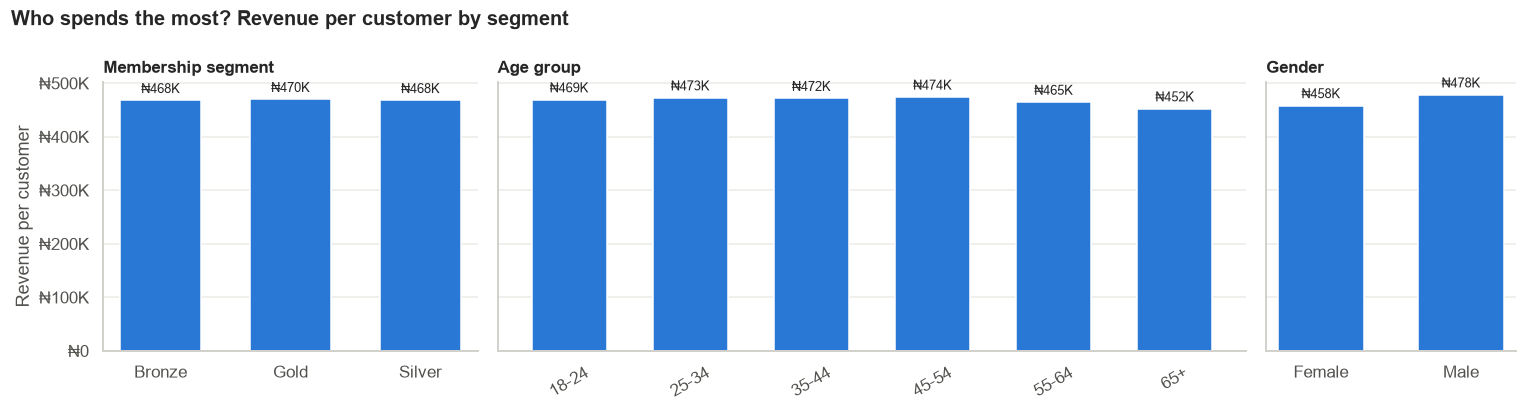

In [58]:
def spend_by(col: str) -> pd.DataFrame:
    """Revenue per customer and AOV for a customer attribute."""
    grp = done_fe.groupby(col, observed=True)
    out = pd.DataFrame({"customers": grp["customer_id"].nunique(), "revenue": grp["net_sales"].sum(),
                        "aov": grp["net_sales"].mean()})
    out["revenue_per_customer"] = out["revenue"] / out["customers"]
    out["share_of_revenue"] = out["revenue"] / out["revenue"].sum()
    return out


segment_views = {
    "Membership segment": spend_by("customer_segment"),
    "Age group": spend_by("customer_age_group"),
    "Gender": spend_by("gender"),
}

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True, gridspec_kw={"width_ratios": [3, 6, 2]})
for ax, (title, view) in zip(axes, segment_views.items()):
    bars = ax.bar(view.index.astype(str), view["revenue_per_customer"], color=PRIMARY, width=0.62)
    ax.bar_label(bars, labels=[naira(v, digits=0) for v in view["revenue_per_customer"]], padding=3, fontsize=8.5)
    ax.set_title(title, fontsize=11)
    ax.tick_params(axis="x", rotation=30 if len(view) > 3 else 0)
    ax.grid(axis="x", visible=False)
axes[0].yaxis.set_major_formatter(NAIRA_AXIS)
axes[0].set_ylabel("Revenue per customer")
fig.suptitle("Who spends the most? Revenue per customer by segment", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "15_spend_by_customer_segment")

pd.concat(segment_views, names=["view", "group"]).style.format(
    {"customers": "{:,}", "revenue": "₦{:,.0f}", "aov": "₦{:,.0f}", "revenue_per_customer": "₦{:,.0f}",
     "share_of_revenue": "{:.1%}"})

In [59]:
# Customers use several channels and payment methods, so "revenue per customer" is not comparable
# there. Compare them by average order value and share of revenue instead.
pd.concat({col: done_fe.groupby(col, observed=True)["net_sales"].agg(aov="mean", revenue="sum")
           .assign(share_of_revenue=lambda d: d["revenue"] / d["revenue"].sum())
           for col in ["sales_channel", "payment_method"]}, names=["view", "group"])     .style.format({"aov": "₦{:,.0f}", "revenue": "₦{:,.0f}", "share_of_revenue": "{:.1%}"})

In [60]:
seg = segment_views["Membership segment"]
insights["top_segment"] = seg["revenue_per_customer"].idxmax()
age = segment_views["Age group"]
insights["top_age_group"] = age["revenue_per_customer"].idxmax()
print("Highest spend per customer: segment =", insights["top_segment"], "| age group =", insights["top_age_group"])
print("Spread between highest and lowest age group:",
      f"{age['revenue_per_customer'].max() / age['revenue_per_customer'].min() - 1:.1%}")
print("Spread between highest and lowest membership segment:",
      f"{seg['revenue_per_customer'].max() / seg['revenue_per_customer'].min() - 1:.1%}")

Highest spend per customer: segment = Gold | age group = 45-54
Spread between highest and lowest age group: 4.8%
Spread between highest and lowest membership segment: 0.4%


**Answer:** Spending per customer is **almost identical across segments**:

* **Membership:** Gold, Silver and Bronze customers spend within **0.4%** of each other (about ₦470K
  each in 2025). Each tier contributes about a third of revenue.
* **Age:** the 45–54 group spends the most per customer, and 65+ the least, but the gap is under 5%.
  The **55–64 group is the largest revenue pool** (19.5%), because it has the most customers.
* **Gender:** male customers spend about 4% more per customer (₦478K against ₦458K). The gap is small,
  and gender labels are unreliable (Part 3i), so it is not a basis for targeting.
* **Sales channel and payment method:** online and in-store orders, and card, cash and transfer
  payments, have near-identical order values and each take an equal share of revenue.

**Business meaning:** the membership tiers do **not** change spending, since Gold members spend the
same as Bronze members. The loyalty programme is not producing higher-value behaviour and its
benefits should be reviewed. As Part 6 showed, the real difference between customers is **how often
they buy**.

### Q4. Which products have high return rates?

Every product has about 100 orders, so a few returns can push its rate up by chance. To separate
real problems from noise, each product's return rate is compared with a **binomial test** against
the overall rate. Products are flagged only if p < 0.05.

In [61]:
from scipy.stats import binomtest

overall_return_rate = sales_fe["is_returned"].mean()
prod_returns = sales_fe.groupby(["product_name", "category"], observed=True).agg(
    orders=("order_id", "count"), returns=("is_returned", "sum"))
prod_returns["return_rate"] = prod_returns["returns"] / prod_returns["orders"]
prod_returns["p_value"] = [binomtest(int(r), int(n), overall_return_rate, alternative="greater").pvalue
                           for r, n in zip(prod_returns["returns"], prod_returns["orders"])]
prod_returns["significant"] = prod_returns["p_value"] < 0.05
high_returns = prod_returns.sort_values("return_rate", ascending=False)
insights["high_return_products"] = int(prod_returns["significant"].sum())
insights["top_return_product"] = high_returns.index[0][0]
insights["top_return_rate"] = float(high_returns["return_rate"].iloc[0])
print(f"Overall return rate: {overall_return_rate:.2%}")
print(f"Products with a significantly high return rate (p < 0.05): {prod_returns['significant'].sum()} of {len(prod_returns)}")
high_returns.head(10).style.format({"return_rate": "{:.1%}", "p_value": "{:.4f}"})

Overall return rate: 4.88%
Products with a significantly high return rate (p < 0.05): 12 of 500


,,orders,returns,return_rate,p_value,significant
product_name,category,,,,,
Home Item 263,Home,95,11,11.6%,0.0067,True
Beauty Item 262,Beauty,88,10,11.4%,0.0108,True
Beauty Item 443,Beauty,92,10,10.9%,0.0144,True
Fashion Item 349,Fashion,94,10,10.6%,0.0166,True
Home Item 5,Home,96,10,10.4%,0.0190,True
Beauty Item 191,Beauty,89,9,10.1%,0.0299,True
Home Item 142,Home,91,9,9.9%,0.0339,True
Beauty Item 271,Beauty,92,9,9.8%,0.0360,True
Beauty Item 6,Beauty,73,7,9.6%,0.0655,False


In [62]:
reasons = (clean["returns"].merge(sales_fe[["order_id", "category"]], on="order_id")
           .pipe(lambda d: pd.crosstab(d["category"], d["return_reason"], normalize="index")))
reasons.style.format("{:.0%}").background_gradient(cmap="Blues", axis=None)

return_reason,Customer Changed Mind,Damaged,Late Delivery,Wrong Item
category,,,,
Beauty,21%,24%,30%,26%
Electronics,28%,22%,26%,24%
Fashion,25%,29%,23%,23%
Groceries,27%,18%,27%,28%
Home,25%,26%,23%,26%


**Answer:** **Home Item 263** has the highest return rate (11.6%), and the top products are returned
**more than twice as often as average** (about 10–12% against 4.9%). Only **12 of 500 products** are
significantly above average (p < 0.05). They should be checked first for quality, description or
supplier problems. Everything else is within normal variation.

Return reasons are split almost evenly: **Late Delivery 26%, Wrong Item 25%**, Customer Changed Mind
25% and Damaged 24%. Beauty has the most late-delivery returns (30%), and Fashion the most damaged
items (29%). **About half of all returns (late delivery plus wrong item) are operational failures
that ShopSmart controls**, not product defects.

### Q5. Which months have peak sales?

In [63]:
month_perf = summarise(done_fe, "order_month").sort_index()
month_perf["days"] = done_fe.groupby("order_month")["order_date"].nunique()
month_perf["revenue_per_day"] = month_perf["revenue"] / month_perf["days"]
month_perf.index = pd.to_datetime(month_perf.index.astype(str), format="%m").strftime("%b")
insights["peak_month"] = month_perf["revenue"].idxmax()
insights["peak_month_revenue"] = float(month_perf["revenue"].max())
insights["low_month"] = month_perf["revenue"].idxmin()
month_perf[["revenue", "completed_orders", "aov", "revenue_per_day"]].style.format(PERF_FMT | {"revenue_per_day": "₦{:,.0f}"}) \
    .highlight_max(subset=["revenue", "revenue_per_day"], color="#d6e6f9")

,revenue,completed_orders,aov,revenue_per_day
order_month,,,,
Jan,"₦193,227,919","1,424","₦135,694","₦6,233,159"
Feb,"₦170,700,588","1,261","₦135,369","₦6,096,450"
Mar,"₦191,870,552","1,413","₦135,789","₦6,189,373"
Apr,"₦189,823,299","1,408","₦134,818","₦6,327,443"
May,"₦183,029,363","1,346","₦135,980","₦5,904,173"
Jun,"₦174,649,130","1,326","₦131,711","₦5,821,638"
Jul,"₦187,964,797","1,415","₦132,837","₦6,063,381"
Aug,"₦183,394,826","1,360","₦134,849","₦5,915,962"
Sep,"₦186,066,858","1,357","₦137,116","₦6,202,229"


**Answer:** **December** (₦201M) is the peak, then **October** (₦197M) and January (₦193M).
December is also the best month per trading day. This fits the festive season, and Q4 is the
strongest quarter. February is the lowest in total but only because it is short. May–June is the
real soft patch per day. Seasonality is mild, about ±7% around the monthly average.

### Q6. Which categories are growing?

With one year of data, growth is measured as **Q4 vs Q1 revenue** and shown as an index (Q1 = 100).

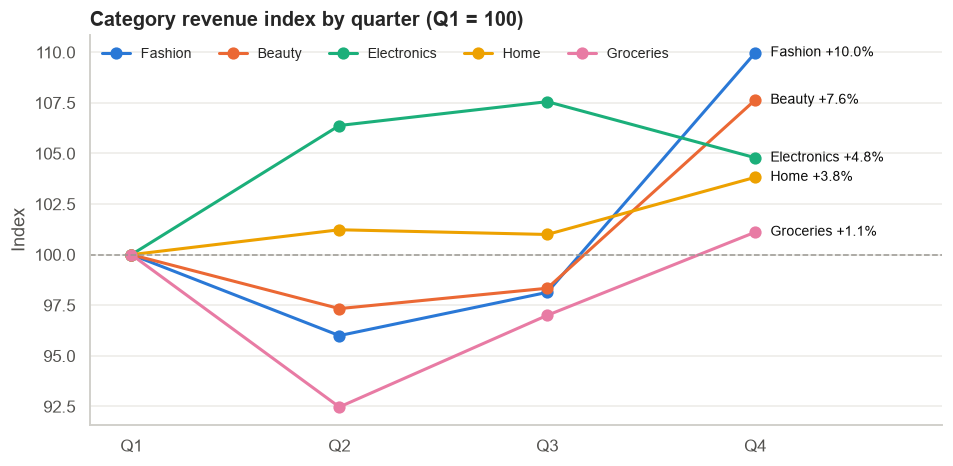

,Q4 vs Q1 growth
category,
Fashion,+10.0%
Beauty,+7.6%
Electronics,+4.8%
Home,+3.8%
Groceries,+1.1%


In [64]:
cat_q = done_fe.pivot_table(index="order_quarter", columns="category", values="net_sales",
                            aggfunc="sum", observed=True)
cat_index = cat_q / cat_q.iloc[0] * 100
growth = (cat_q.iloc[-1] / cat_q.iloc[0] - 1).sort_values(ascending=False)
insights["category_growth"] = {k: float(v) for k, v in growth.items()}

fig, ax = plt.subplots(figsize=(10, 4.6))
cat_order = growth.index.tolist()                          # legend in growth order
for color, cat in zip(CATEGORICAL, cat_order):
    ax.plot(cat_index.index, cat_index[cat], marker="o", markersize=7, linewidth=2, color=color, label=cat)
    ax.annotate(f"{cat} {growth[cat]:+.1%}", (cat_index.index[-1], cat_index[cat].iloc[-1]),
                textcoords="offset points", xytext=(10, 0), va="center", fontsize=9, color="#0b0b0b")
ax.axhline(100, color=MUTED, linewidth=1, linestyle="--")
ax.set_xlim(-0.2, 3.9)
ax.set_title("Category revenue index by quarter (Q1 = 100)")
ax.set_ylabel("Index")
ax.legend(loc="upper left", frameon=False, ncol=5, fontsize=9)
ax.grid(axis="x", visible=False)
save_fig(fig, "16_category_growth")
growth.to_frame("Q4 vs Q1 growth").style.format("{:+.1%}")

**Answer:** Every category grew from Q1 to Q4. **Fashion (+10%) and Beauty (+8%)** grew fastest,
followed by Electronics (+5%) and Home (+4%). **Groceries was flat (+1%)**. Beauty is the largest
category *and* one of the fastest growing, which makes it the strongest candidate for investment.
Fashion's growth comes mostly from Q4, so it may be seasonal. A second year of data is needed to confirm it.

### Q7. Which suppliers perform best?

Each supplier is linked to products through the brand (Part 3h). Almost every supplier supplies
exactly one product, so suppliers are also compared by **country**.

In [65]:
supplier_perf = summarise(done_fe, "supplier_name").join(
    clean["suppliers"].set_index("supplier_name")["country"])
insights["best_supplier"] = supplier_perf.index[0]
supplier_perf.head(10).style.format(PERF_FMT)

,revenue,profit,completed_orders,units,aov,margin,all_orders,completion_rate,return_rate,country
supplier_name,,,,,,,,,,
Thomas Ltd Supplies,"₦10,593,852","₦4,502,250",77,221,"₦137,582",42.5%,211,36.5%,4.74%,Usa
Williams Group Supplies,"₦9,442,355","₦3,790,559",69,200,"₦136,846",40.1%,213,32.4%,5.16%,Germany
Martinez Ltd Supplies,"₦9,248,003","₦3,324,628",64,191,"₦144,500",35.9%,211,30.3%,5.69%,Usa
Matthews and Sons Supplies,"₦8,941,216","₦4,500,336",68,194,"₦131,488",50.3%,195,34.9%,4.10%,China
Smith PLC Supplies,"₦8,653,078","₦3,510,463",64,191,"₦135,204",40.6%,179,35.8%,3.91%,China
Smith LLC Supplies,"₦8,625,804","₦1,127,029",68,203,"₦126,850",13.1%,206,33.0%,3.88%,Germany
Jones Group Supplies,"₦8,408,558","₦6,054,186",64,178,"₦131,384",72.0%,204,31.4%,5.39%,Germany
Garcia PLC Supplies,"₦8,318,017","₦1,380,270",65,195,"₦127,969",16.6%,203,32.0%,2.96%,Nigeria
Myers and Sons Supplies,"₦8,206,686","₦3,803,158",61,190,"₦134,536",46.3%,208,29.3%,4.81%,Germany


In [66]:
supplier_country = clean["suppliers"][["supplier_id", "country"]]
country_perf = summarise(done_fe.merge(supplier_country, on="supplier_id"), "country",
                         all_orders=sales_fe.merge(supplier_country, on="supplier_id"))
country_perf["suppliers"] = clean["suppliers"].groupby("country", observed=True).size()
country_perf.style.format(PERF_FMT)

,revenue,profit,completed_orders,units,aov,margin,all_orders,completion_rate,return_rate,suppliers
country,,,,,,,,,,
Germany,"₦595,739,641","₦227,142,519","4,386","13,168","₦135,828",38.1%,"13,305",33.0%,4.98%,127
China,"₦554,292,566","₦237,980,802","4,132","12,373","₦134,146",42.9%,"12,367",33.4%,4.54%,122
Nigeria,"₦549,550,550","₦265,955,977","3,974","11,876","₦138,286",48.4%,"12,037",33.0%,4.88%,118
Usa,"₦547,255,073","₦273,017,699","4,037","12,015","₦135,560",49.9%,"12,291",32.8%,5.13%,122


In [67]:
print(f"Suppliers whose products lost money overall in 2025: {(supplier_perf['profit'] < 0).sum()}")
supplier_perf.sort_values("profit").head(5)[["country", "revenue", "profit", "margin"]].style.format(PERF_FMT)

Suppliers whose products lost money overall in 2025: 56


,country,revenue,profit,margin
supplier_name,,,,
Scott-Shelton Supplies,Germany,"₦4,602,332","₦-1,852,688",-40.3%
Cooke Inc Supplies,Germany,"₦2,764,683","₦-1,100,139",-39.8%
"Warner, Booker and Pineda Supplies",China,"₦5,310,099","₦-1,035,797",-19.5%
Valdez Ltd Supplies,Germany,"₦3,618,599","₦-911,161",-25.2%
Richardson LLC Supplies,China,"₦3,946,155","₦-879,303",-22.3%


**Answer:** By revenue, **Thomas Ltd Supplies** performs best (₦10.6M from two products at a 43%
margin), followed by Williams Group and Martinez Ltd. Most suppliers supply one product, and a few
supply two.

By sourcing country, revenue is evenly split, but **margins are not**:
**US (50%) and Nigerian (48%) suppliers are the most profitable**, while **German suppliers have the
lowest margin (38%)** despite the highest revenue. Return rates are similar (4.5–5.1%). In addition,
**56 suppliers' products lost money overall**. Their purchase prices, or ShopSmart's selling prices
for those products, need to be renegotiated.

The supplier table has no delivery dates, lead times or fill rates, so true supplier performance
(on-time delivery, quality) **cannot be measured** yet. ShopSmart should start capturing this data.

### Q8. Which inventory items require restocking?

In [68]:
restock = (inventory_features[inventory_features["inventory_status"] == "Low"]
           .sort_values("stock_cover")
           [["product_name", "category", "store_label", "stock_on_hand", "reorder_level", "stock_cover",
             "avg_daily_units_sold", "days_of_supply"]])
insights["restock_items"] = int(len(restock))
restock.to_csv(CLEAN_DIR / "restock_list.csv", index=False)
print(f"{len(restock)} items are at or below their reorder level (saved to Cleaned_Data/restock_list.csv)")
restock.head(15).style.format({"stock_cover": "{:.2f}", "avg_daily_units_sold": "{:.2f}", "days_of_supply": "{:.0f}"})

21 items are at or below their reorder level (saved to Cleaned_Data/restock_list.csv)


,product_name,category,store_label,stock_on_hand,reorder_level,stock_cover,avg_daily_units_sold,days_of_supply
211,Home Item 212,Home,Awka (STR022),12,41,0.29,0.25,48
413,Home Item 414,Home,Ibadan (STR009),13,44,0.30,0.27,48
301,Home Item 302,Home,Lagos (STR013),14,46,0.30,0.21,67
164,Electronics Item 165,Electronics,Port Harcourt (STR014),14,45,0.31,0.28,49
478,Beauty Item 479,Beauty,Abuja (STR017),10,29,0.34,0.29,34
370,Beauty Item 371,Beauty,Ibadan (STR018),16,41,0.39,0.21,77
145,Electronics Item 146,Electronics,Lagos (STR021),21,47,0.45,0.36,58
58,Fashion Item 59,Fashion,Kano (STR002),11,23,0.48,0.27,41
271,Fashion Item 272,Fashion,Abuja (STR001),16,29,0.55,0.29,55
477,Home Item 478,Home,Kaduna (STR006),28,50,0.56,0.25,111


In [69]:
status_by_store = pd.crosstab(inventory_features["store_label"], inventory_features["inventory_status"])
status_by_store = status_by_store.reindex(columns=["Low", "Medium", "High"]).sort_values("Low", ascending=False)
status_by_store.head(8)

inventory_status,Low,Medium,High
store_label,,,
Kaduna (STR006),3,2,17
Port Harcourt (STR014),3,4,13
Ibadan (STR018),2,0,15
Ibadan (STR009),2,1,17
Abuja (STR001),2,3,14
Asaba (STR020),1,3,23
Abuja (STR017),1,3,21
Asaba (STR025),1,8,14


**Answer:** The items listed above are at or below their reorder level and should be **restocked
now**, starting with the lowest stock cover. The full list is saved as `Cleaned_Data/restock_list.csv`.
Most inventory is classed **High** (more than 3× the reorder level). ShopSmart's bigger stock problem
is **overstock**, since ₦3.2B is tied up at cost. Excess stock should be moved from overstocked stores
to the stores with Low items.

### Q9. Which regions underperform?

Regions are measured with the corrected `geo_zone` (Part 3e) and normalised **per store**. Zones with
more stores always have more total revenue, so the total alone is misleading.

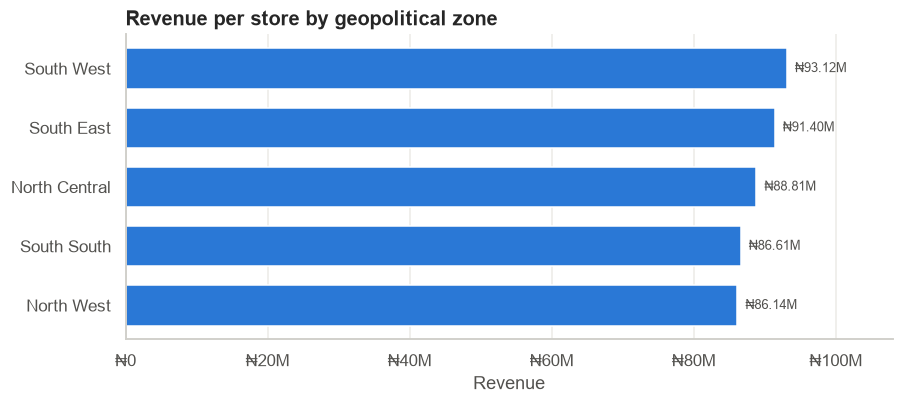

,stores,revenue,revenue_per_store,aov,completion_rate,return_rate
geo_zone,,,,,,
South West,10,"₦931,158,925","₦93,115,892","₦136,714",33.9%,4.93%
South East,2,"₦182,807,120","₦91,403,560","₦136,423",33.2%,4.69%
North Central,4,"₦355,241,789","₦88,810,447","₦136,579",32.3%,5.04%
South South,5,"₦433,055,406","₦86,611,081","₦136,654",32.1%,5.00%
North West,4,"₦344,574,591","₦86,143,648","₦132,122",32.9%,4.57%


In [70]:
zone_perf = summarise(done_fe, "geo_zone")
zone_perf["stores"] = clean["stores"].groupby("geo_zone", observed=True).size()
zone_perf["revenue_per_store"] = zone_perf["revenue"] / zone_perf["stores"]
zone_perf = zone_perf.sort_values("revenue_per_store", ascending=False)
insights["best_zone"] = zone_perf.index[0]
insights["worst_zone"] = zone_perf.index[-1]

fig, ax = plt.subplots(figsize=(9, 3.6))
barh_ranked(zone_perf["revenue_per_store"], "Revenue per store by geopolitical zone", ax=ax)
save_fig(fig, "17_revenue_per_store_by_zone")
zone_perf[["stores", "revenue", "revenue_per_store", "aov", "completion_rate", "return_rate"]].style.format(
    PERF_FMT | {"revenue_per_store": "₦{:,.0f}"})

**Answer:** On a per-store basis the **North West** (Kano and Kaduna, ₦86.1M per store) and **South
South** (Delta and Rivers, ₦86.6M) underperform. Kano (STR002) is the weakest store in the network.
**South West** stores perform best (₦93.1M per store), then the South East (₦91.4M). The gap between
the best and worst zone is about **8%**: real, but modest. Completion rate is again the main
difference (South West 33.9% against about 32% in the weaker zones).

With the original `region` field, the regional picture would be meaningless, because it puts Lagos
in all four regions.

### Q10. What patterns could support predictive modelling?

In [71]:
status_by = {
    "sales_channel": pd.crosstab(sales_fe["sales_channel"], sales_fe["order_status"], normalize="index"),
    "payment_method": pd.crosstab(sales_fe["payment_method"], sales_fe["order_status"], normalize="index"),
    "customer_segment": pd.crosstab(sales_fe["customer_segment"], sales_fe["order_status"], normalize="index"),
}
pd.concat(status_by, names=["driver", "value"]).style.format("{:.1%}")

**Answer:** Patterns that are useful (or *not* useful) for machine learning:

| Pattern | Evidence | Modelling use |
|---------|----------|---------------|
| Mild Q4 / December seasonality | Monthly trend, Q5 | **Sales forecasting**: month and quarter features, festive-season uplift |
| Purchase frequency drives customer value | r = 0.79 between completed orders and revenue (Part 6) | **CLV and churn models**: recency and frequency features (Part 7) |
| Two thirds of orders are not completed | Part 4 | **Order completion prediction**: the largest revenue lever. Status mix is flat across channel, payment and segment, so new signals are needed (cart events, stock availability, delivery slot) |
| Order value = price × quantity | r = 0.72 / 0.60 | **Order value regression** is easy, but must avoid target leakage |
| Returns uncorrelated with any variable | Part 6 | **Return prediction** needs new data: delivery times, product reviews, customer return history |
| 24% of order lines sold below cost | Part 3g / 7 | **Anomaly detection** on pricing, flagging below-cost sales in real time |
| Uneven stock against demand | Q8, Part 5.10 | **Inventory forecasting**: days of supply and stock cover as features |
| Product co-purchase by the same customer | 10 orders per customer on average | **Product recommendation** (market-basket or collaborative filtering) |

**Caveat:** the data shows very little variation between groups (stores, segments, categories, age).
It appears to be synthetic or heavily balanced, so models trained on it would have limited
predictive power. They should be validated on real transaction data.

In [72]:
with open(CLEAN_DIR / "insights.json", "w", encoding="utf-8") as fh:
    json.dump(insights, fh, indent=2, ensure_ascii=False, default=str)
insights

{'top_product': 'Beauty Item 210',
 'top_product_revenue': 7375596.4,
 'best_store': 'Lagos (STR003)',
 'best_store_revenue': 102203162.7,
 'worst_store': 'Kano (STR002)',
 'worst_store_revenue': 81066968.25,
 'top_segment': 'Gold',
 'top_age_group': '45-54',
 'high_return_products': 12,
 'top_return_product': 'Home Item 263',
 'top_return_rate': 0.11578947368421053,
 'peak_month': 'Dec',
 'peak_month_revenue': 201038740.75,
 'low_month': 'Feb',
 'category_growth': {'Fashion': 0.09971952319519128,
  'Beauty': 0.07641594642603877,
  'Electronics': 0.04788640707481551,
  'Home': 0.038206887983488924,
  'Groceries': 0.011103998749040223},
 'best_supplier': 'Thomas Ltd Supplies',
 'restock_items': 21,
 'best_zone': 'South West',
 'worst_zone': 'North West'}